<a href="https://colab.research.google.com/github/madhuraspatil/Internal-Assisment/blob/main/BANK_DATASET_AIML_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ARTIFICIAL AND MACHINE LEARNING PROJECT**

GROUP MEMBERS NAME:

         ABHISHEK PATIL(202401040050)

         PARTH WANKHADE(202401040052)

         MADHURA PATIL(202401040094)

## Dataset Description and SDG Relevance

The **Bank Marketing Dataset** used in this project is an official dataset obtained from the **UCI Machine Learning Repository**. It contains data related to direct marketing campaigns conducted by a Portuguese banking institution to promote term deposit subscriptions among customers. The dataset includes 41,188 customer records and 20 input features, such as age, job, marital status, education, account-related information, contact details, and previous campaign history. The target variable, `y`, indicates whether a customer subscribed to a term deposit (`yes` or `no`). The main objective of this project is to analyze customer information and develop a machine learning model that predicts the likelihood of a customer subscribing to a term deposit. This can help financial institutions understand customer behavior, improve marketing strategies, and make more informed, data-driven decisions.

### Sustainable Development Goals (SDG) Relevance

This project is indirectly related to the United Nations Sustainable Development Goals (SDGs), particularly:

- **SDG 8 – Decent Work and Economic Growth:** Supports improved financial services and more efficient banking operations through data-driven customer analysis.
- **SDG 9 – Industry, Innovation and Infrastructure:** Demonstrates the use of machine learning and data analytics to encourage technological innovation in the banking and financial sector.

Although the original dataset was not specifically designed to achieve these SDGs, this project demonstrates how machine learning can contribute to more efficient and technology-driven financial services.

### Step 1: Importing Required Libraries

Imported Python libraries such as Pandas and NumPy for data handling and numerical calculations. Matplotlib and Seaborn were used for data visualization. Requests and Zipfile were used to download and extract the dataset. OS and BytesIO were used for file and memory operations. These libraries provided all the necessary tools for data analysis and machine learning.

In [ ]:
# STEP 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import zipfile
import requests
import os
from io import BytesIO

print("Libraries imported successfully!")

Libraries imported successfully!


### Step 0: Coonect Google Drive

Connection to Google Drive was done to see the variation in the result after each operation and each steps either csv or png was saved in drive.

In [ ]:
# STEP 0: CONNECT GOOGLE DRIVE

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Project folder
project_path = "/content/drive/MyDrive/AIML project"

# Create folder if it does not exist
os.makedirs(project_path, exist_ok=True)

print("Google Drive Connected Successfully!")
print("Project Folder:", project_path)

Mounted at /content/drive
Google Drive Connected Successfully!
Project Folder: /content/drive/MyDrive/AIML project


### Step 2: Dataset Collection and Loading

Downloaded the Bank Marketing dataset from the UCI Machine Learning Repository using the Requests library. The dataset was available in ZIP format, so we extracted the required CSV file using the Zipfile library. Pandas was used to load the CSV file into a DataFrame named `df`. The dataset contains 41,188 records and 21 columns, including 20 input features and one target variable (`y`). This dataset will be used to build a machine learning model that predicts customer subscription to a bank term deposit.

In [ ]:
# STEP 2A: Inspect ZIP File Structure

print("Files available in the downloaded ZIP:\n")

for file_name in zip_file.namelist():
    print(file_name)

Files available in the downloaded ZIP:

bank.zip
bank-additional.zip


In [ ]:
# STEP 2B: Inspect the Nested ZIP

import io
import zipfile

with zip_file.open("bank-additional.zip") as nested_file:

    nested_zip = zipfile.ZipFile(io.BytesIO(nested_file.read()))

    print("Files inside bank-additional.zip:\n")

    for file_name in nested_zip.namelist():
        print(file_name)

Files inside bank-additional.zip:

bank-additional/
bank-additional/.DS_Store
__MACOSX/
__MACOSX/bank-additional/
__MACOSX/bank-additional/._.DS_Store
bank-additional/.Rhistory
bank-additional/bank-additional-full.csv
bank-additional/bank-additional-names.txt
bank-additional/bank-additional.csv
__MACOSX/._bank-additional


In [ ]:
# STEP 2C: Load the Bank Marketing Dataset

# Open the nested ZIP file
with zip_file.open("bank-additional.zip") as nested_file:

    nested_zip = zipfile.ZipFile(io.BytesIO(nested_file.read()))

    # Open the full dataset CSV
    with nested_zip.open(
        "bank-additional/bank-additional-full.csv"
    ) as csv_file:

        # Load dataset
        df = pd.read_csv(csv_file, sep=";")

# Verify dataset
print("DATASET LOADED SUCCESSFULLY!")

print("\nDataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

DATASET LOADED SUCCESSFULLY!

Dataset Shape: (41188, 21)

Number of Rows: 41188
Number of Columns: 21

First 5 Records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Column Names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


### Step 3: Dataset Quality Audit

Performed a detailed quality check of the dataset to understand its structure, data types, missing values, unknown values, and duplicate records. Analyzed the target variable distribution to identify class imbalance and separated numerical and categorical features. This step helped identify data quality issues and understand the dataset before starting data cleaning and preprocessing.

In [ ]:
# STEP 3: DATASET QUALITY AUDIT

print("=" * 60)
print("1. DATASET INFORMATION")
print("=" * 60)

print("Shape:", df.shape)
print("\nData Types and Non-Null Counts:")
df.info()


print("\n" + "=" * 60)
print("2. MISSING VALUES")
print("=" * 60)

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing[missing["Missing Count"] > 0])

if df.isnull().sum().sum() == 0:
    print("No actual null values found!")


print("\n" + "=" * 60)
print("3. UNKNOWN VALUES")
print("=" * 60)

unknown_counts = {}

for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()

    if count > 0:
        unknown_counts[col] = count

unknown_df = pd.DataFrame(
    list(unknown_counts.items()),
    columns=["Column", "Unknown Count"]
)

display(unknown_df)


print("\n" + "=" * 60)
print("4. DUPLICATE RECORDS")
print("=" * 60)

print("Duplicate Rows:", df.duplicated().sum())


print("\n" + "=" * 60)
print("5. TARGET VARIABLE DISTRIBUTION")
print("=" * 60)

print(df["y"].value_counts())

print("\nTarget Percentage:")
print((df["y"].value_counts(normalize=True) * 100).round(2))


print("\n" + "=" * 60)
print("6. NUMERICAL AND CATEGORICAL FEATURES")
print("=" * 60)

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Columns:", numerical_columns)
print("\nNumber of Numerical Columns:", len(numerical_columns))

print("\nCategorical Columns:", categorical_columns)
print("\nNumber of Categorical Columns:", len(categorical_columns))

1. DATASET INFORMATION
Shape: (41188, 21)

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  c

,Missing Count,Missing Percentage


No actual null values found!

3. UNKNOWN VALUES


,Column,Unknown Count
0,job,330
1,marital,80
2,education,1731
3,default,8597
4,housing,990
5,loan,990



4. DUPLICATE RECORDS
Duplicate Rows: 12

5. TARGET VARIABLE DISTRIBUTION
y
no     36548
yes     4640
Name: count, dtype: int64

Target Percentage:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

6. NUMERICAL AND CATEGORICAL FEATURES
Numerical Columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of Numerical Columns: 10

Categorical Columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']

Number of Categorical Columns: 11


### Step 4: Saving Original Dataset and Inspection Report

Saved the original dataset without making any modifications as `01_original_dataset.csv` to preserve the raw data. Created a separate inspection report containing total rows, columns, missing values, duplicate records, unknown values, and target distribution. Calculated the count and percentage of each category to summarize the dataset quality. Saved the report as `02_data_inspection.csv` in Google Drive for future reference and documentation.

In [ ]:
# STEP 4: SAVE ORIGINAL DATASET AND INSPECTION REPORT

# 1. Save the original dataset without any changes
original_path = os.path.join(project_path, "01_original_dataset.csv")
df.to_csv(original_path, index=False)

# 2. Prepare dataset inspection report
inspection_data = []

inspection_data.append({
    "Category": "Dataset Information",
    "Item": "Total Rows",
    "Count": df.shape[0],
    "Percentage": 100
})

inspection_data.append({
    "Category": "Dataset Information",
    "Item": "Total Columns",
    "Count": df.shape[1],
    "Percentage": 100
})

inspection_data.append({
    "Category": "Data Quality",
    "Item": "Actual Missing Values",
    "Count": df.isnull().sum().sum(),
    "Percentage": 0
})

inspection_data.append({
    "Category": "Data Quality",
    "Item": "Duplicate Rows",
    "Count": df.duplicated().sum(),
    "Percentage": round(df.duplicated().mean() * 100, 2)
})

# Unknown values
for column in df.select_dtypes(include="object").columns:
    count = (df[column] == "unknown").sum()

    if count > 0:
        inspection_data.append({
            "Category": "Unknown Values",
            "Item": column,
            "Count": count,
            "Percentage": round((count / len(df)) * 100, 2)
        })

# Target distribution
for value, count in df["y"].value_counts().items():
    inspection_data.append({
        "Category": "Target Distribution",
        "Item": value,
        "Count": count,
        "Percentage": round((count / len(df)) * 100, 2)
    })

inspection_df = pd.DataFrame(inspection_data)

# 3. Save inspection report
inspection_path = os.path.join(project_path, "02_data_inspection.csv")
inspection_df.to_csv(inspection_path, index=False)

# 4. Confirm saved files
print("Files saved successfully in Google Drive!")
print("\nOriginal Dataset:", original_path)
print("Inspection Report:", inspection_path)

print("\nInspection Report:")
display(inspection_df)

Files saved successfully in Google Drive!

Original Dataset: /content/drive/MyDrive/AIML project/01_original_dataset.csv
Inspection Report: /content/drive/MyDrive/AIML project/02_data_inspection.csv

Inspection Report:


,Category,Item,Count,Percentage
0,Dataset Information,Total Rows,41188,100.00
1,Dataset Information,Total Columns,21,100.00
2,Data Quality,Actual Missing Values,0,0.00
3,Data Quality,Duplicate Rows,12,0.03
4,Unknown Values,job,330,0.80
5,Unknown Values,marital,80,0.19
6,Unknown Values,education,1731,4.20
7,Unknown Values,default,8597,20.87
8,Unknown Values,housing,990,2.40
9,Unknown Values,loan,990,2.40


### Step 5: Removing Duplicate Records

Checked the original dataset to identify duplicate records before cleaning.  
Removed duplicate rows using the `drop_duplicates()` method while preserving the original dataset.  
Verified that no duplicate records remained in the cleaned dataset.  
Calculated the total number of records removed and checked the updated dataset size.  
Saved the cleaned dataset as `03_duplicates_removed.csv` in Google Drive.

In [ ]:
# STEP 5: REMOVE DUPLICATE RECORDS

# 1. Check duplicate records before removal
duplicates_before = df.duplicated().sum()

print("Duplicate Records Before Removal:", duplicates_before)
print("Original Dataset Shape:", df.shape)

# 2. Create a separate cleaned dataset
df_cleaned = df.drop_duplicates().copy()

# 3. Check duplicate records after removal
duplicates_after = df_cleaned.duplicated().sum()

print("\nDuplicate Records After Removal:", duplicates_after)
print("Cleaned Dataset Shape:", df_cleaned.shape)

# 4. Calculate removed records
removed_records = len(df) - len(df_cleaned)

print("\nTotal Duplicate Records Removed:", removed_records)

# 5. Save cleaned dataset in Google Drive
cleaned_path = os.path.join(
    project_path,
    "03_duplicates_removed.csv"
)

df_cleaned.to_csv(cleaned_path, index=False)

print("\nCleaned dataset saved successfully!")
print("File Location:", cleaned_path)

Duplicate Records Before Removal: 12
Original Dataset Shape: (41188, 21)

Duplicate Records After Removal: 0
Cleaned Dataset Shape: (41176, 21)

Total Duplicate Records Removed: 12

Cleaned dataset saved successfully!
File Location: /content/drive/MyDrive/AIML project/03_duplicates_removed.csv


### Step 6: Analysing Unknown Values

Identified all categorical columns in the cleaned dataset.  
Counted the number of `unknown` entries present in each categorical column.  
Calculated the percentage of unknown values for every affected column.  
Created a separate summary report to understand the distribution of unknown values.  
Saved the analysis as `04_unknown_values_analysis.csv` in Google Drive.

In [ ]:
# STEP 6: ANALYSE UNKNOWN VALUES

# 1. Identify categorical columns
categorical_columns = df_cleaned.select_dtypes(
    include="object"
).columns.tolist()

# 2. Count unknown values in each categorical column
unknown_summary = []

for column in categorical_columns:

    count = (df_cleaned[column] == "unknown").sum()

    if count > 0:
        percentage = (count / len(df_cleaned)) * 100

        unknown_summary.append({
            "Column": column,
            "Unknown Count": count,
            "Percentage": round(percentage, 2)
        })

unknown_df = pd.DataFrame(unknown_summary)

print("Unknown Values Analysis:")
display(unknown_df)

# 3. Save analysis separately in Google Drive
unknown_path = os.path.join(
    project_path,
    "04_unknown_values_analysis.csv"
)

unknown_df.to_csv(unknown_path, index=False)

print("Unknown values analysis saved successfully!")
print("File Location:", unknown_path)

Unknown Values Analysis:


,Column,Unknown Count,Percentage
0,job,330,0.80
1,marital,80,0.19
2,education,1730,4.20
3,default,8596,20.88
4,housing,990,2.40
5,loan,990,2.40


Unknown values analysis saved successfully!
File Location: /content/drive/MyDrive/AIML project/04_unknown_values_analysis.csv


### Step 7: Handling Unknown Values

Created a separate dataset from the duplicate-free dataset for handling unknown values.  
Retained `unknown` entries as a separate category instead of deleting or replacing them.  
Checked the dataset to confirm that no actual missing values were present.  
Counted the total unknown values retained across all categorical columns.  
Saved the updated dataset as `05_unknown_values_handled.csv` in Google Drive.

In [ ]:
# STEP 7: HANDLE UNKNOWN VALUES

# 1. Create a separate dataset
df_unknown_handled = df_cleaned.copy()

# 2. Retain unknown as a separate category
print("Unknown values are retained as a separate category.")

# 3. Check actual missing values
print("\nActual Missing Values:")
print(df_unknown_handled.isnull().sum().sum())

# 4. Count remaining unknown values
total_unknown = 0

for column in df_unknown_handled.select_dtypes(include="object").columns:
    total_unknown += (df_unknown_handled[column] == "unknown").sum()

print("\nTotal Unknown Values Retained:", total_unknown)

# 5. Save dataset in Google Drive
unknown_handled_path = os.path.join(
    project_path,
    "05_unknown_values_handled.csv"
)

df_unknown_handled.to_csv(
    unknown_handled_path,
    index=False
)

print("\nDataset saved successfully!")
print("File Location:", unknown_handled_path)
print("Final Dataset Shape:", df_unknown_handled.shape)

Unknown values are retained as a separate category.

Actual Missing Values:
0

Total Unknown Values Retained: 12716

Dataset saved successfully!
File Location: /content/drive/MyDrive/AIML project/05_unknown_values_handled.csv
Final Dataset Shape: (41176, 21)


### Step 8: Target Variable Distribution

Analysed the distribution of the target variable `y`, which represents term deposit subscription.  
Counted the customers in each category (`yes` and `no`) and calculated their percentages.  
Created a count plot to visually compare customers who subscribed and those who did not.  
Prepared a summary containing customer counts and percentages for both categories.  
Saved the results as `06_target_distribution.csv` in Google Drive.

Target Variable Distribution:
y
no     36537
yes     4639
Name: count, dtype: int64

Target Variable Percentage:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


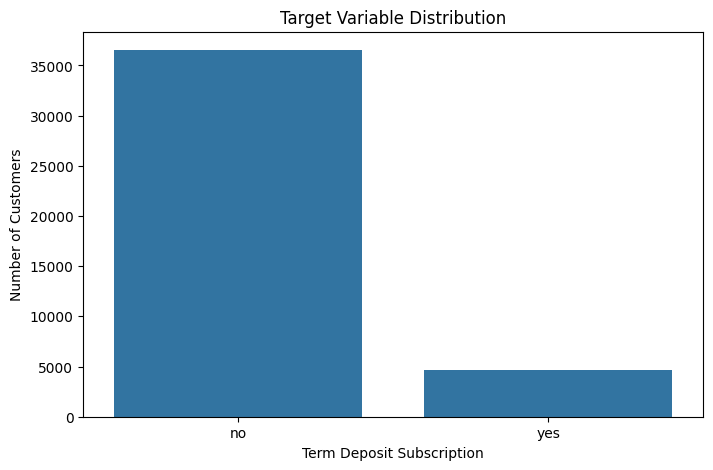


Target distribution saved successfully!
File Location: /content/drive/MyDrive/AIML project/06_target_distribution.csv


In [ ]:
# STEP 8: TARGET VARIABLE DISTRIBUTION

# Count target categories
target_counts = df_unknown_handled["y"].value_counts()

print("Target Variable Distribution:")
print(target_counts)

# Calculate percentages
target_percentage = (
    df_unknown_handled["y"].value_counts(normalize=True) * 100
)

print("\nTarget Variable Percentage:")
print(target_percentage.round(2))

# Create visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_unknown_handled,
    x="y"
)

plt.title("Target Variable Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()

# Save target distribution separately
target_df = pd.DataFrame({
    "Subscription": target_counts.index,
    "Customer_Count": target_counts.values,
    "Percentage": target_percentage.loc[target_counts.index].round(2).values
})

target_path = os.path.join(
    project_path,
    "06_target_distribution.csv"
)

target_df.to_csv(target_path, index=False)

print("\nTarget distribution saved successfully!")
print("File Location:", target_path)

### Step 9: Numerical Features Statistical Analysis

Selected the following numerical columns for statistical analysis: `age`, `duration`, `campaign`, `pdays`, `previous`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, and `nr.employed`.  
Calculated descriptive statistics, including count, mean, standard deviation, minimum, maximum, and quartiles.  
Calculated the median separately to understand the central value of each numerical feature.  
Displayed the statistical summary to understand the distribution and range of numerical data.  
Saved the results as `07_numerical_statistics.csv` in Google Drive.

In [ ]:
# STEP 9: NUMERICAL FEATURES STATISTICAL ANALYSIS

# Select numerical columns
numerical_columns = df_unknown_handled.select_dtypes(
    include=np.number
).columns.tolist()

# Generate descriptive statistics
numerical_summary = df_unknown_handled[
    numerical_columns
].describe().T

# Add median separately for clarity
numerical_summary["median"] = (
    df_unknown_handled[numerical_columns].median()
)

# Display results
print("Numerical Features Statistical Summary:")
display(numerical_summary.round(2))

# Save statistical summary in Google Drive
statistics_path = os.path.join(
    project_path,
    "07_numerical_statistics.csv"
)

numerical_summary.to_csv(statistics_path)

print("\nStatistical summary saved successfully!")
print("File Location:", statistics_path)

Numerical Features Statistical Summary:


,count,mean,std,min,25%,50%,75%,max,median
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00,38.00
duration,41176.0,258.32,259.31,0.00,102.00,180.00,319.00,4918.00,180.00
campaign,41176.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00,2.00
pdays,41176.0,962.46,186.94,0.00,999.00,999.00,999.00,999.00,999.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00,0.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40,1.10
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77,93.75
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90,-41.80
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04,4.86
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10,5191.00



Statistical summary saved successfully!
File Location: /content/drive/MyDrive/AIML project/07_numerical_statistics.csv


### Step 10: Numerical Features Distribution

Selected all numerical columns from the dataset and analysed their distributions using histograms with KDE curves.  
Created a 4 × 3 grid of plots to visualize the distribution of each numerical feature.  
Used 30 bins in each histogram to understand data frequency, spread, and distribution patterns.  
Generated descriptive statistics for all numerical features to support the visual analysis.  
Saved the statistical summary as `08_numerical_distribution_summary.csv` in Google Drive.

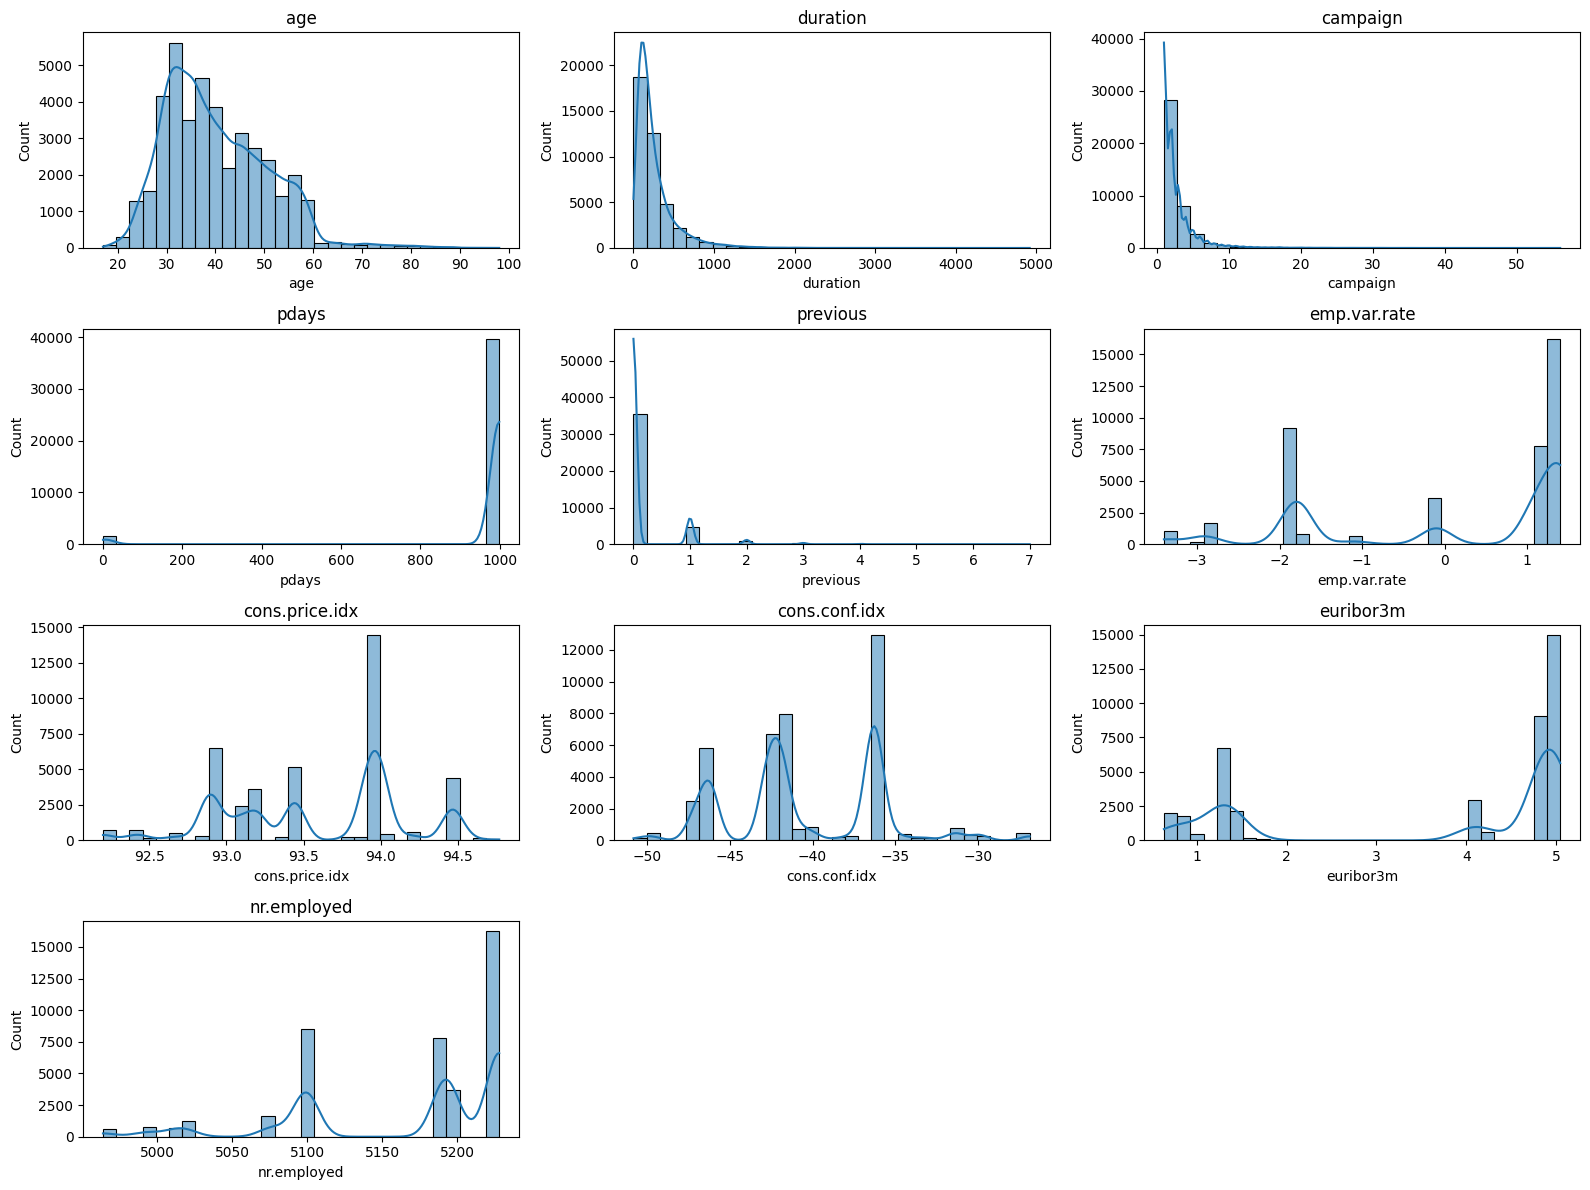

Numerical distribution summary saved successfully!
File Location: /content/drive/MyDrive/AIML project/08_numerical_distribution_summary.csv


In [ ]:
# STEP 10: NUMERICAL FEATURES DISTRIBUTION

numerical_columns = df_unknown_handled.select_dtypes(
    include=np.number
).columns.tolist()

plt.figure(figsize=(16, 12))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(4, 3, i)

    sns.histplot(
        data=df_unknown_handled,
        x=column,
        kde=True,
        bins=30
    )

    plt.title(column)

plt.tight_layout()
plt.show()

# Save numerical distribution data
distribution_summary = df_unknown_handled[
    numerical_columns
].describe().T

distribution_path = os.path.join(
    project_path,
    "08_numerical_distribution_summary.csv"
)

distribution_summary.to_csv(distribution_path)

print("Numerical distribution summary saved successfully!")
print("File Location:", distribution_path)

### Step 11: Categorical Features Analysis

Selected all categorical input columns, excluding the target variable `y`.  
Created count plots to visualize the distribution of categories in each feature.  
Displayed categories in descending order based on the number of customers.  
Calculated the customer count and percentage for every category in each categorical feature.  
Saved the visualization as `10_categorical_features_distribution.png` and the summary as `11_categorical_features_summary.csv` in Google Drive.

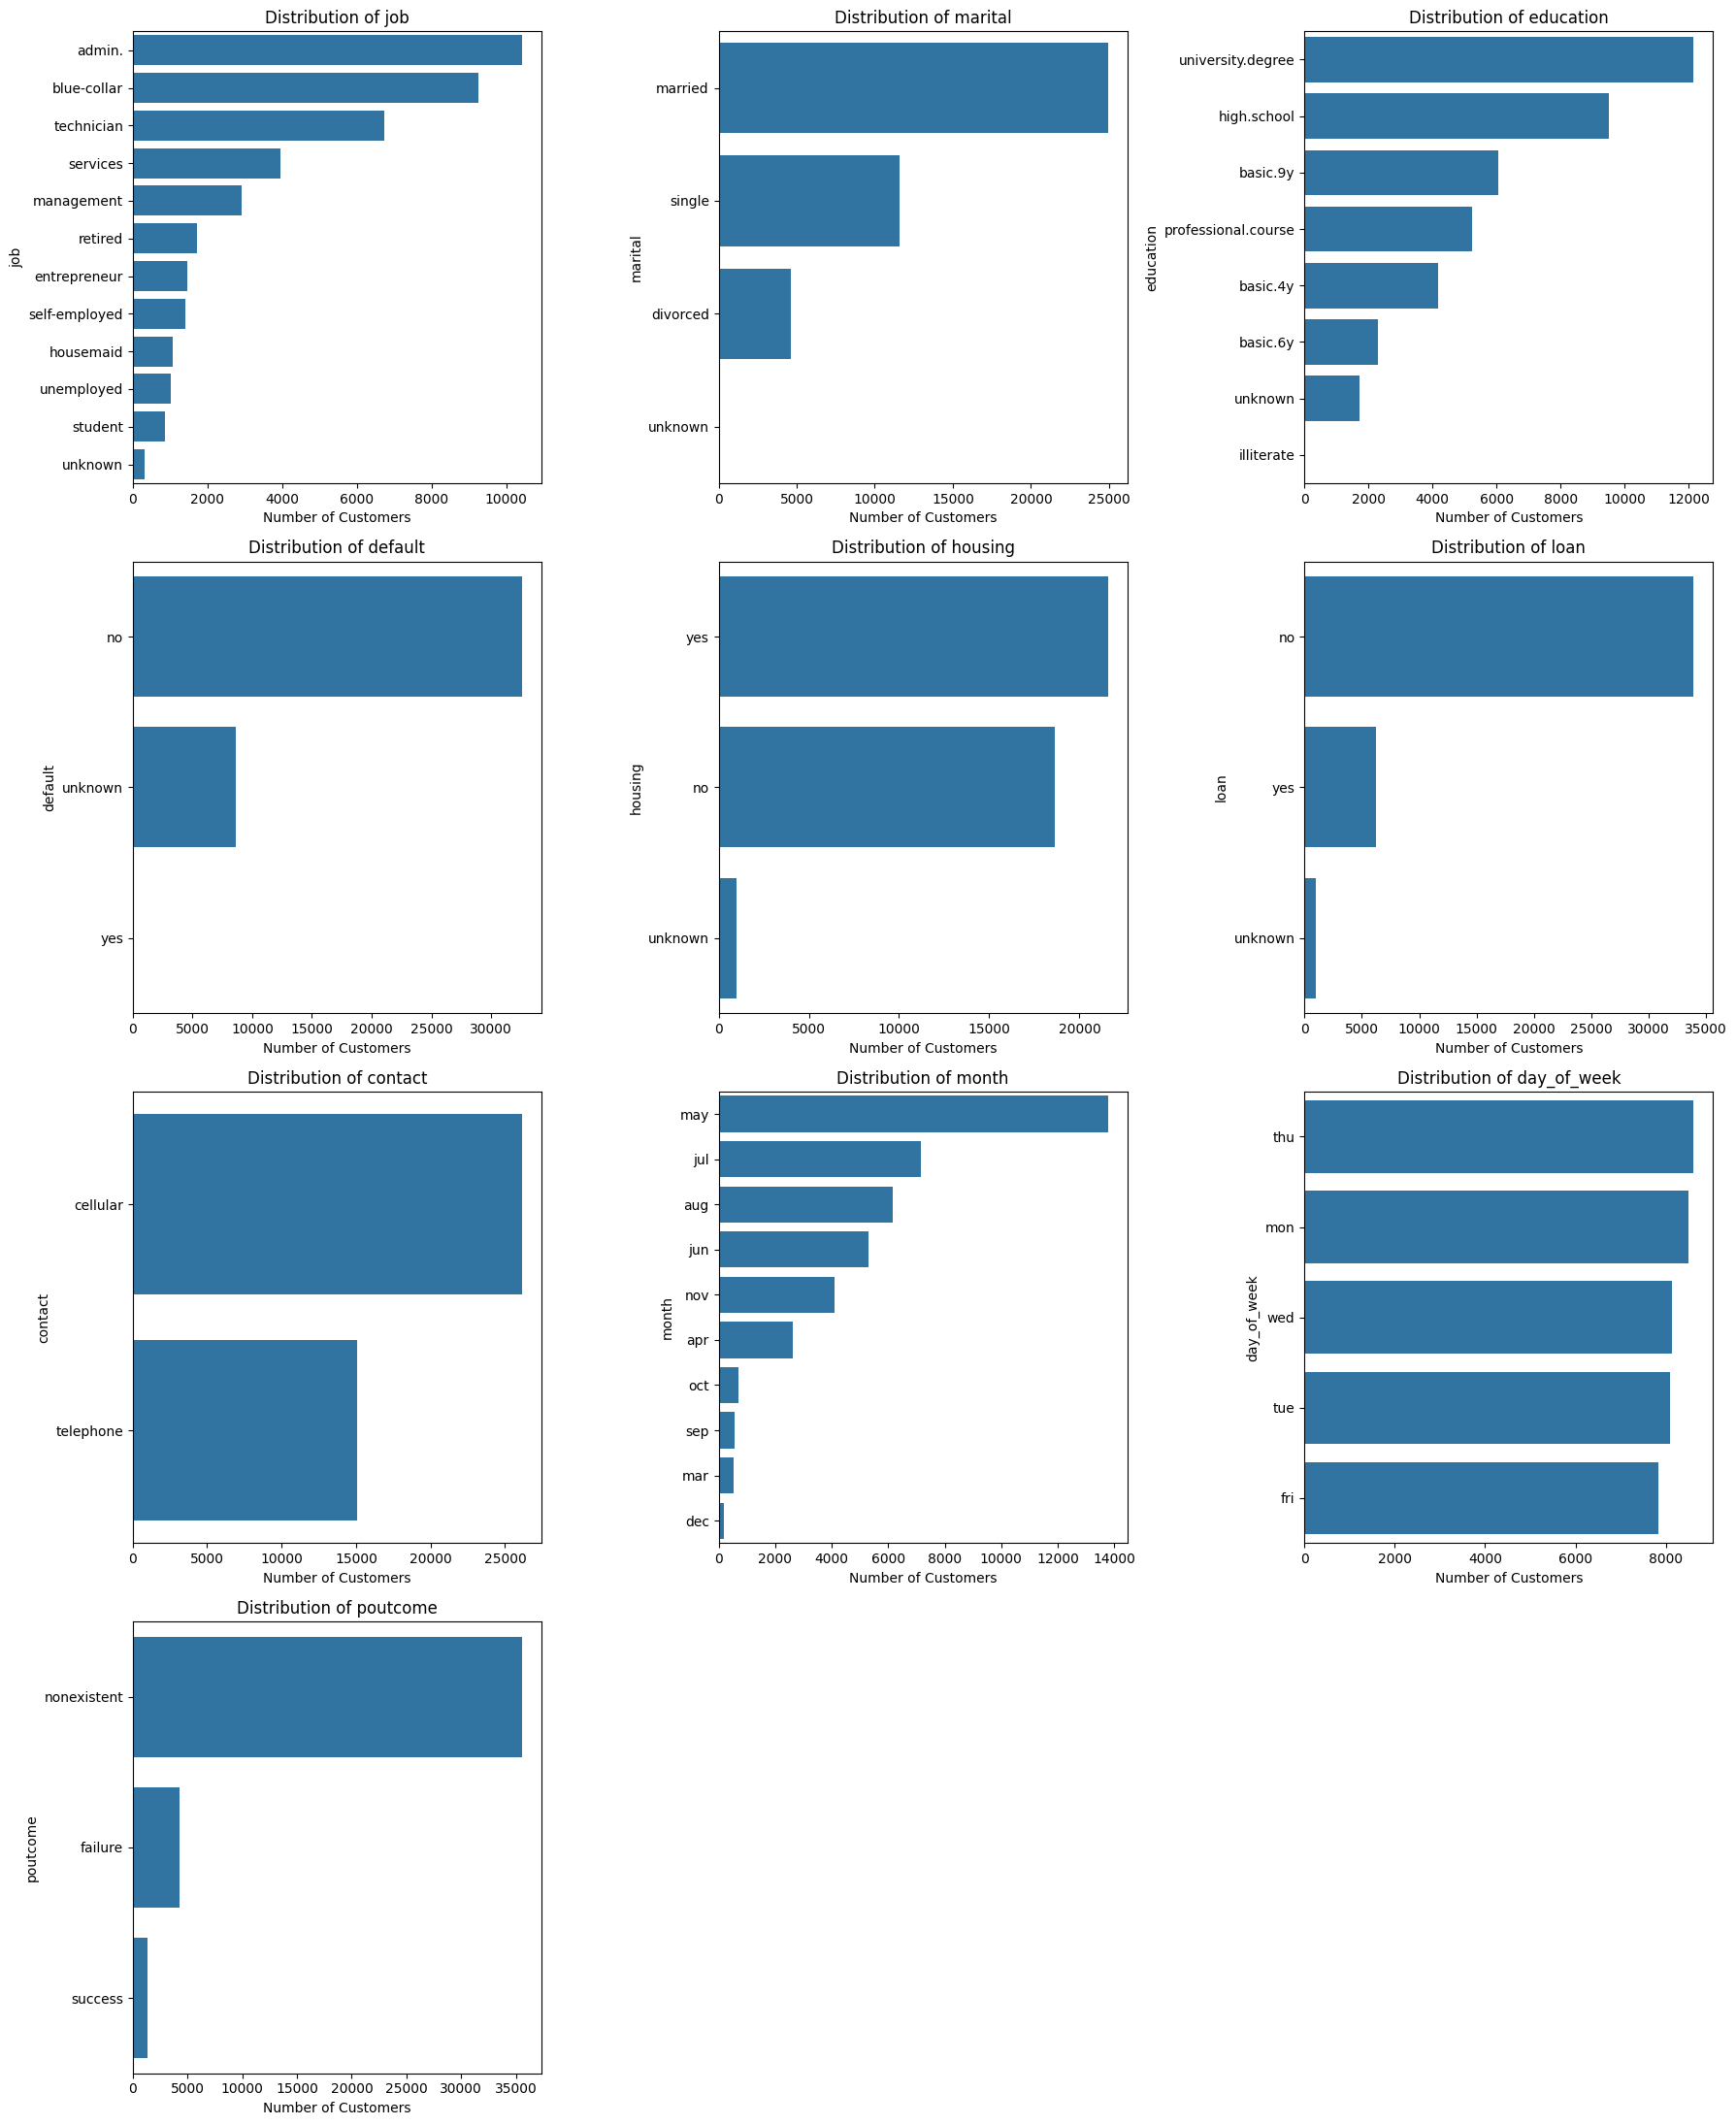

Categorical analysis completed!
Graph saved: /content/drive/MyDrive/AIML project/10_categorical_features_distribution.png
Summary saved: /content/drive/MyDrive/AIML project/11_categorical_features_summary.csv


,Feature,Category,Customer_Count,Percentage
0,job,admin.,10419,25.30
1,job,blue-collar,9253,22.47
2,job,technician,6739,16.37
3,job,services,3967,9.63
4,job,management,2924,7.10
5,job,retired,1718,4.17
6,job,entrepreneur,1456,3.54
7,job,self-employed,1421,3.45
8,job,housemaid,1060,2.57
9,job,unemployed,1014,2.46


In [ ]:
# STEP 11: CATEGORICAL FEATURES ANALYSIS

# 1. Select categorical input columns
categorical_columns = [
    column for column in df_unknown_handled.select_dtypes(
        include="object"
    ).columns
    if column != "y"
]

# 2. Create plots
plt.figure(figsize=(18, 22))

for i, column in enumerate(categorical_columns, 1):

    plt.subplot(4, 3, i)

    sns.countplot(
        data=df_unknown_handled,
        y=column,
        order=df_unknown_handled[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel("Number of Customers")
    plt.ylabel(column)

plt.tight_layout()

# 3. Save graph
categorical_graph_path = os.path.join(
    project_path,
    "10_categorical_features_distribution.png"
)

plt.savefig(
    categorical_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Create categorical summary
categorical_summary = []

for column in categorical_columns:

    counts = df_unknown_handled[column].value_counts()

    for category, count in counts.items():

        categorical_summary.append({
            "Feature": column,
            "Category": category,
            "Customer_Count": count,
            "Percentage": round(
                (count / len(df_unknown_handled)) * 100, 2
            )
        })

categorical_summary_df = pd.DataFrame(categorical_summary)

# 5. Save summary CSV
categorical_path = os.path.join(
    project_path,
    "11_categorical_features_summary.csv"
)

categorical_summary_df.to_csv(
    categorical_path,
    index=False
)

print("Categorical analysis completed!")
print("Graph saved:", categorical_graph_path)
print("Summary saved:", categorical_path)

display(categorical_summary_df.head(20))

### Step 12: Correlation Analysis

Selected all numerical columns from the dataset and calculated their pairwise correlation coefficients.  
Created a correlation matrix to identify the strength and direction of relationships between numerical features.  
Visualized the results using a heatmap with annotated correlation values.  
Used the `coolwarm` colour map to make positive and negative correlations easier to identify.  
Saved the heatmap as `12_correlation_heatmap.png` and the correlation matrix as `12_correlation_matrix.csv` in Google Drive.

Correlation Matrix:


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.00,-0.00,0.00,-0.03,0.02,-0.00,0.00,0.13,0.01,-0.02
duration,-0.00,1.00,-0.07,-0.05,0.02,-0.03,0.01,-0.01,-0.03,-0.04
campaign,0.00,-0.07,1.00,0.05,-0.08,0.15,0.13,-0.01,0.14,0.14
pdays,-0.03,-0.05,0.05,1.00,-0.59,0.27,0.08,-0.09,0.30,0.37
previous,0.02,0.02,-0.08,-0.59,1.00,-0.42,-0.20,-0.05,-0.45,-0.50
emp.var.rate,-0.00,-0.03,0.15,0.27,-0.42,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.00,0.01,0.13,0.08,-0.20,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.13,-0.01,-0.01,-0.09,-0.05,0.20,0.06,1.00,0.28,0.10
euribor3m,0.01,-0.03,0.14,0.30,-0.45,0.97,0.69,0.28,1.00,0.95
nr.employed,-0.02,-0.04,0.14,0.37,-0.50,0.91,0.52,0.10,0.95,1.00


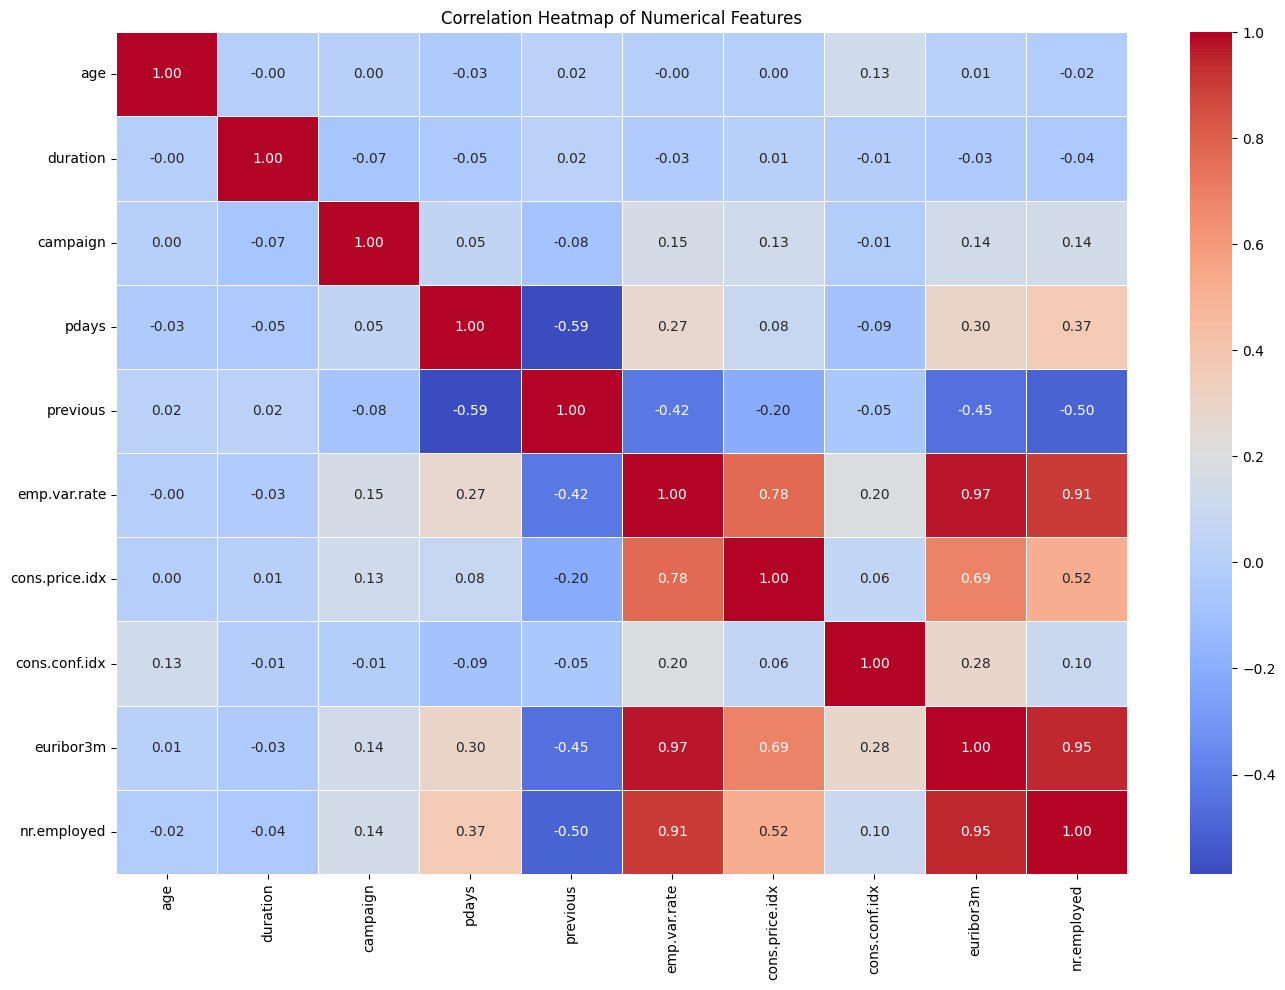

Correlation analysis completed!
Heatmap saved: /content/drive/MyDrive/AIML project/12_correlation_heatmap.png
Correlation matrix saved: /content/drive/MyDrive/AIML project/12_correlation_matrix.csv


In [ ]:
# STEP 12: CORRELATION ANALYSIS

# 1. Select numerical columns
numerical_columns = df_unknown_handled.select_dtypes(
    include=np.number
).columns.tolist()

# 2. Calculate correlation matrix
correlation_matrix = df_unknown_handled[
    numerical_columns
].corr()

# 3. Display correlation matrix
print("Correlation Matrix:")
display(correlation_matrix.round(2))

# 4. Create heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

# 5. Save heatmap
heatmap_path = os.path.join(
    project_path,
    "12_correlation_heatmap.png"
)

plt.savefig(
    heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Save correlation matrix as CSV
correlation_path = os.path.join(
    project_path,
    "12_correlation_matrix.csv"
)

correlation_matrix.to_csv(correlation_path)

print("Correlation analysis completed!")
print("Heatmap saved:", heatmap_path)
print("Correlation matrix saved:", correlation_path)

### Step 13: Outlier Detection Using Boxplots

Selected all numerical columns from the dataset for outlier visualization.  
Generated individual boxplots to examine the spread and identify potential outliers in each numerical feature.  
Displayed all boxplots together in a 4 × 3 grid for easy comparison.  
Used the boxplots to visually identify unusual values and understand the distribution of numerical data.  
Saved the visualization as `13_numerical_features_boxplots.png` in Google Drive.

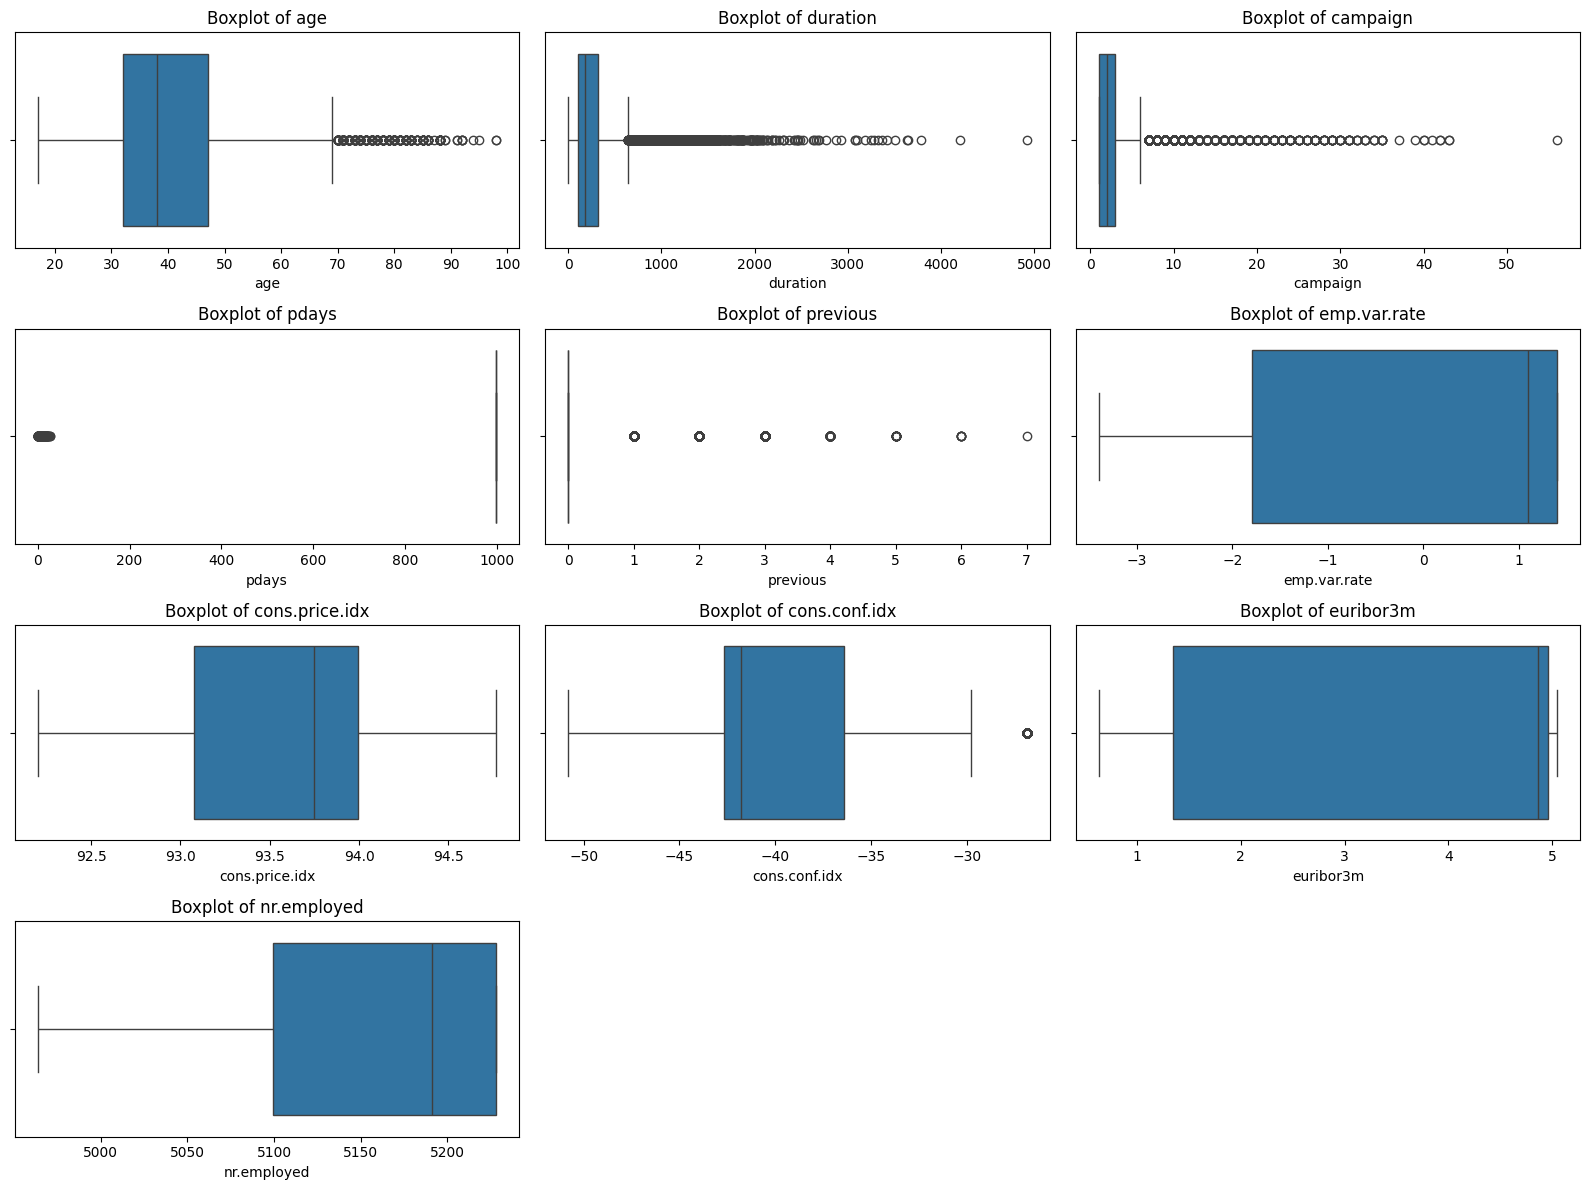

Boxplots generated successfully!
Graph saved: /content/drive/MyDrive/AIML project/13_numerical_features_boxplots.png


In [ ]:
# STEP 13: OUTLIER DETECTION USING BOXPLOTS

# 1. Select numerical columns
numerical_columns = df_unknown_handled.select_dtypes(
    include=np.number
).columns.tolist()

# 2. Create boxplots
plt.figure(figsize=(16, 12))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(4, 3, i)

    sns.boxplot(
        data=df_unknown_handled,
        x=column
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

plt.tight_layout()

# 3. Save boxplot image
boxplot_path = os.path.join(
    project_path,
    "13_numerical_features_boxplots.png"
)

plt.savefig(
    boxplot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Boxplots generated successfully!")
print("Graph saved:", boxplot_path)

### Step 13: IQR Outlier Analysis

Applied the Interquartile Range (IQR) method to detect potential outliers in each numerical feature.  
Calculated Q1, Q3, and IQR to determine the lower and upper limits for every feature.  
Identified values falling below the lower limit or above the upper limit as potential outliers.  
Calculated the outlier count and percentage for each numerical feature.  
Saved the results as `14_outlier_analysis.csv` in Google Drive.

In [ ]:
# STEP 13: IQR OUTLIER ANALYSIS

outlier_summary = []

for column in numerical_columns:

    Q1 = df_unknown_handled[column].quantile(0.25)
    Q3 = df_unknown_handled[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    outliers = df_unknown_handled[
        (df_unknown_handled[column] < lower_limit) |
        (df_unknown_handled[column] > upper_limit)
    ]

    outlier_summary.append({
        "Feature": column,
        "Lower Limit": round(lower_limit, 2),
        "Upper Limit": round(upper_limit, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            (len(outliers) / len(df_unknown_handled)) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

print("IQR Outlier Analysis:")
display(outlier_df)

# Save outlier analysis
outlier_path = os.path.join(
    project_path,
    "14_outlier_analysis.csv"
)

outlier_df.to_csv(outlier_path, index=False)

print("Outlier analysis saved successfully!")
print("File Location:", outlier_path)

IQR Outlier Analysis:


,Feature,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,age,9.50,69.50,468,1.14
1,duration,-223.50,644.50,2963,7.20
2,campaign,-2.00,6.00,2406,5.84
3,pdays,999.00,999.00,1515,3.68
4,previous,0.00,0.00,5625,13.66
5,emp.var.rate,-6.60,6.20,0,0.00
6,cons.price.idx,91.70,95.37,0,0.00
7,cons.conf.idx,-52.15,-26.95,446,1.08
8,euribor3m,-4.08,10.39,0,0.00
9,nr.employed,4905.60,5421.60,0,0.00


Outlier analysis saved successfully!
File Location: /content/drive/MyDrive/AIML project/14_outlier_analysis.csv


### Step 14: Categorical Features vs Target Analysis

Selected all categorical input features, excluding the target variable `y`.  
Calculated the percentage of customers who subscribed (`yes`) and did not subscribe (`no`) within each category.  
Used cross-tabulation to compare subscription rates across different categories.  
Created bar plots to visualize how each categorical feature relates to term deposit subscription.  
Saved the visualization as `15_categorical_vs_target.png` and the analysis as `16_categorical_vs_target_summary.csv` in Google Drive.

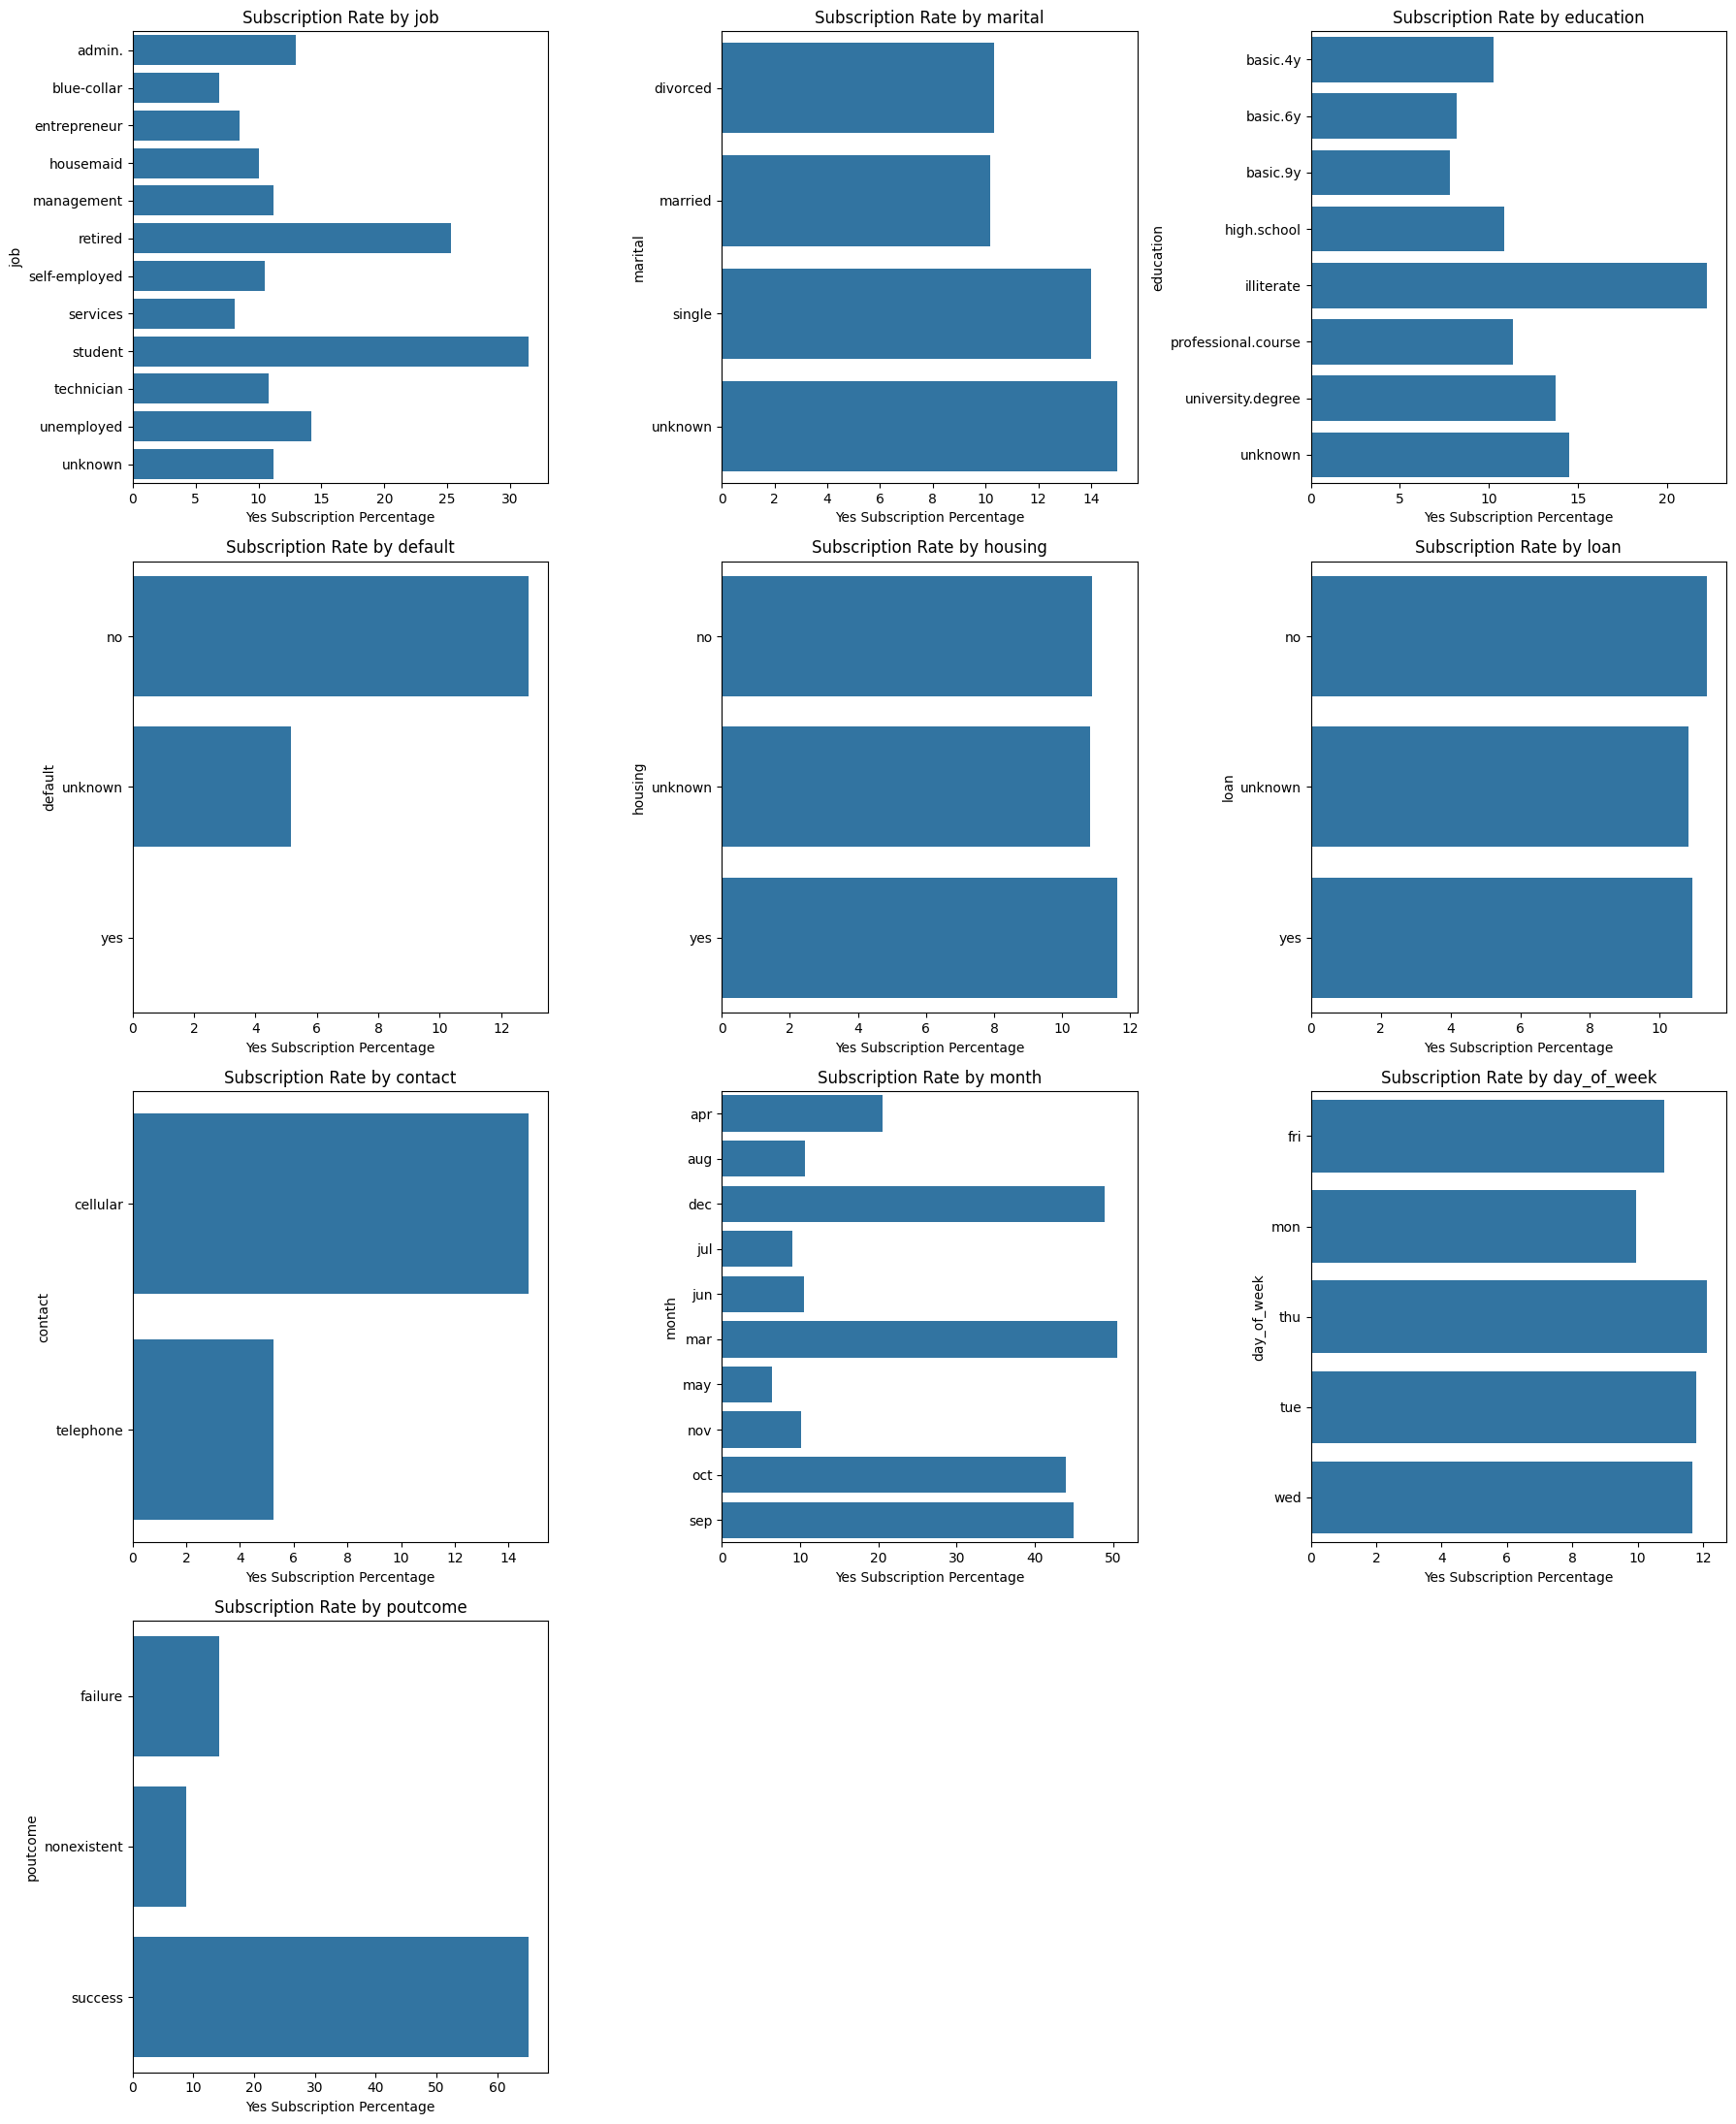

Categorical vs Target Analysis Completed!
Graph saved: /content/drive/MyDrive/AIML project/15_categorical_vs_target.png
Summary saved: /content/drive/MyDrive/AIML project/16_categorical_vs_target_summary.csv


,Feature,Category,No_Percentage,Yes_Percentage
0,job,admin.,87.03,12.97
1,job,blue-collar,93.10,6.90
2,job,entrepreneur,91.48,8.52
3,job,housemaid,90.00,10.00
4,job,management,88.78,11.22
5,job,retired,74.74,25.26
6,job,self-employed,89.51,10.49
7,job,services,91.86,8.14
8,job,student,68.57,31.43
9,job,technician,89.17,10.83


In [ ]:
# STEP 14: CATEGORICAL FEATURES VS TARGET ANALYSIS

# 1. Select categorical input columns
categorical_columns = [
    column for column in df_unknown_handled.select_dtypes(
        include="object"
    ).columns
    if column != "y"
]

# 2. Calculate subscription percentage
categorical_target_summary = []

for column in categorical_columns:

    summary = pd.crosstab(
        df_unknown_handled[column],
        df_unknown_handled["y"],
        normalize="index"
    ) * 100

    for category in summary.index:

        categorical_target_summary.append({
            "Feature": column,
            "Category": category,
            "No_Percentage": round(
                summary.loc[category].get("no", 0), 2
            ),
            "Yes_Percentage": round(
                summary.loc[category].get("yes", 0), 2
            )
        })

categorical_target_df = pd.DataFrame(
    categorical_target_summary
)

# 3. Create subscription rate visualizations
plt.figure(figsize=(18, 22))

for i, column in enumerate(categorical_columns, 1):

    plt.subplot(4, 3, i)

    sns.barplot(
        data=categorical_target_df[
            categorical_target_df["Feature"] == column
        ],
        x="Yes_Percentage",
        y="Category"
    )

    plt.title(f"Subscription Rate by {column}")
    plt.xlabel("Yes Subscription Percentage")
    plt.ylabel(column)

plt.tight_layout()

# 4. Save graph
target_graph_path = os.path.join(
    project_path,
    "15_categorical_vs_target.png"
)

plt.savefig(
    target_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Save analysis CSV
target_summary_path = os.path.join(
    project_path,
    "16_categorical_vs_target_summary.csv"
)

categorical_target_df.to_csv(
    target_summary_path,
    index=False
)

print("Categorical vs Target Analysis Completed!")
print("Graph saved:", target_graph_path)
print("Summary saved:", target_summary_path)

display(categorical_target_df.head(20))

### Step 15: Numerical Features vs Target Analysis

Selected all numerical features from the dataset, excluding categorical columns.  
Created boxplots to compare the distribution of each numerical feature between customers who subscribed (`yes`) and those who did not (`no`).  
Calculated the mean and median values of each numerical feature separately for both target categories.  
Used these visualizations and statistical summaries to understand how numerical features relate to term deposit subscription.  
Saved the graph as `17_numerical_vs_target.png` and the summary as `18_numerical_vs_target_summary.csv` in Google Drive.

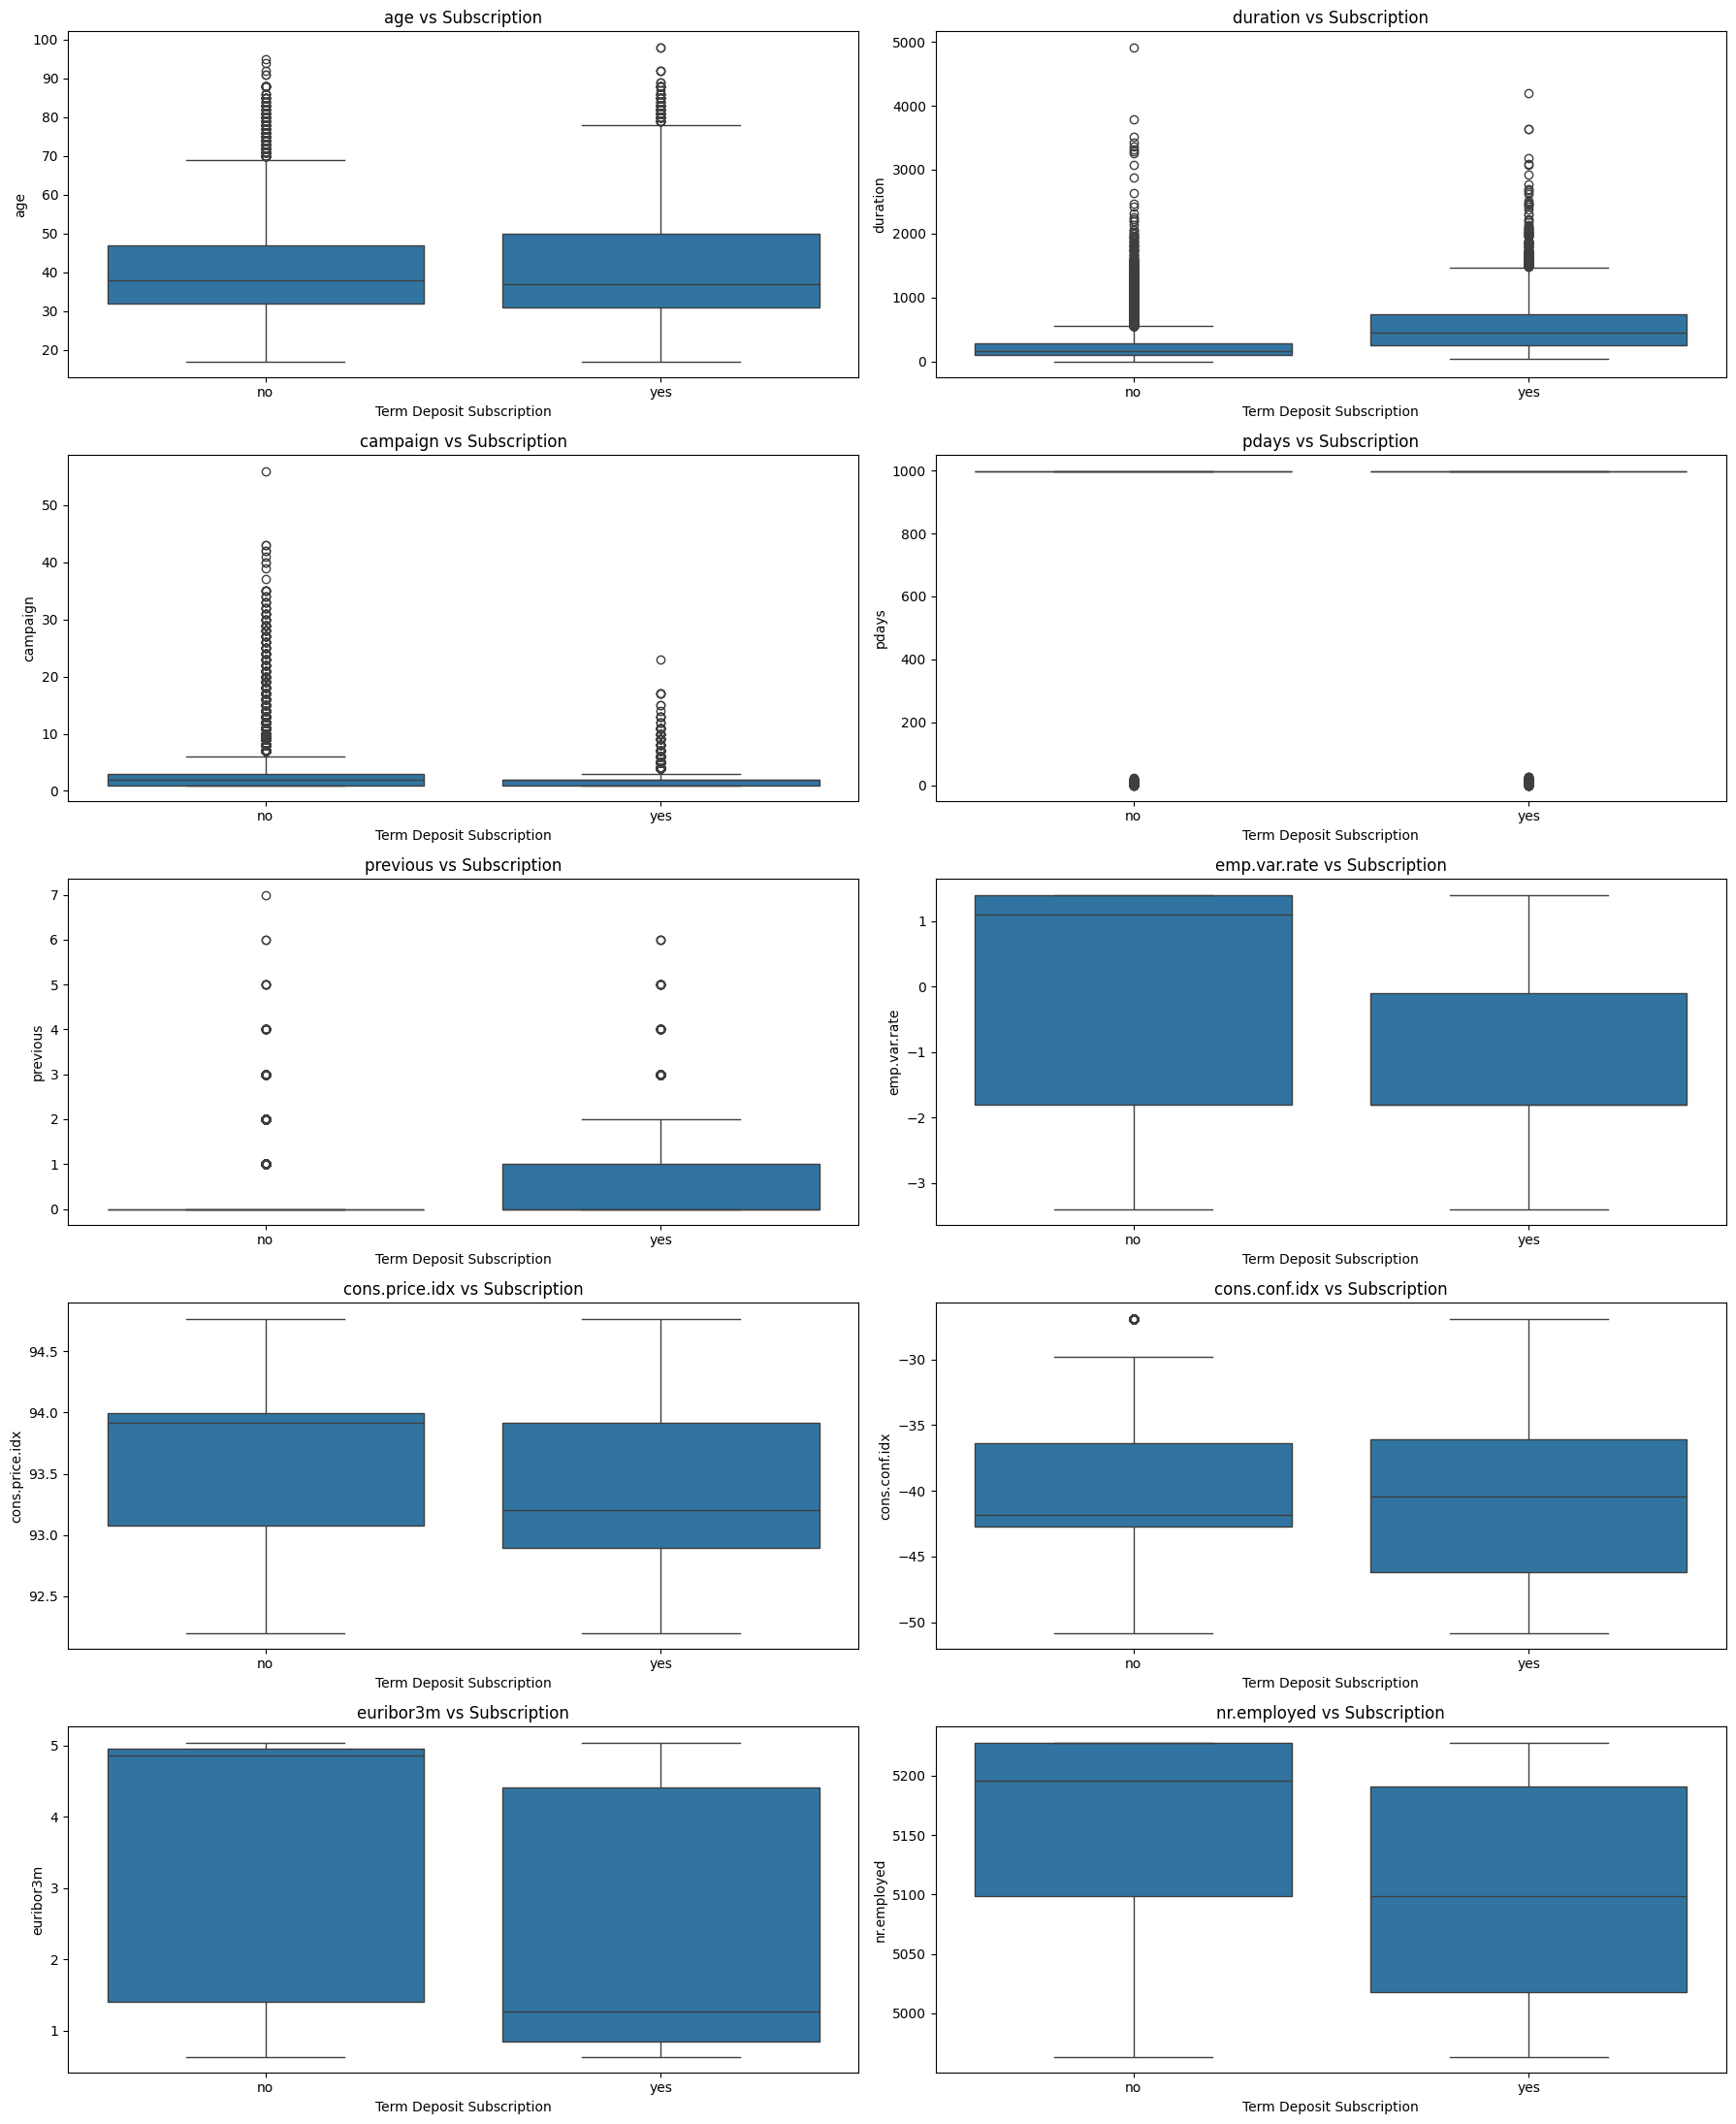

Numerical Features vs Target Summary:


y                           no      yes
age            mean      39.91    40.91
               median    38.00    37.00
duration       mean     220.87   553.26
               median   164.00   449.00
campaign       mean       2.63     2.05
               median     2.00     2.00
pdays          mean     984.11   791.99
               median   999.00   999.00
previous       mean       0.13     0.49
               median     0.00     0.00
emp.var.rate   mean       0.25    -1.23
               median     1.10    -1.80
cons.price.idx mean      93.60    93.35
               median    93.92    93.20
cons.conf.idx  mean     -40.59   -39.79
               median   -41.80   -40.40
euribor3m      mean       3.81     2.12
               median     4.86     1.27
nr.employed    mean    5176.17  5095.12
               median  5195.80  5099.10


Numerical vs Target Analysis Completed!
Graph saved: /content/drive/MyDrive/AIML project/17_numerical_vs_target.png
Summary saved: /content/drive/MyDrive/AIML project/18_numerical_vs_target_summary.csv


In [ ]:
# STEP 15: NUMERICAL FEATURES VS TARGET ANALYSIS

# 1. Select numerical columns
numerical_columns = df_unknown_handled.select_dtypes(
    include=np.number
).columns.tolist()

# 2. Create boxplots
plt.figure(figsize=(18, 22))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(5, 2, i)

    sns.boxplot(
        data=df_unknown_handled,
        x="y",
        y=column
    )

    plt.title(f"{column} vs Subscription")
    plt.xlabel("Term Deposit Subscription")
    plt.ylabel(column)

plt.tight_layout()

# 3. Save graph
numerical_target_graph_path = os.path.join(
    project_path,
    "17_numerical_vs_target.png"
)

plt.savefig(
    numerical_target_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Calculate group-wise statistics
numerical_target_summary = (
    df_unknown_handled
    .groupby("y")[numerical_columns]
    .agg(["mean", "median"])
    .T
)

print("Numerical Features vs Target Summary:")
display(numerical_target_summary.round(2))

# 5. Save summary CSV
numerical_target_path = os.path.join(
    project_path,
    "18_numerical_vs_target_summary.csv"
)

numerical_target_summary.to_csv(numerical_target_path)

print("\nNumerical vs Target Analysis Completed!")
print("Graph saved:", numerical_target_graph_path)
print("Summary saved:", numerical_target_path)

### Step 16: Feature Engineering

Created a separate dataset to add new features without modifying the existing data.  
Introduced `previously_contacted` to indicate whether a customer had been contacted in an earlier campaign.  
Converted the special `pdays` value of `999` into `NaN` and created `days_since_previous_contact` to represent the actual number of days since the previous contact.  
Removed the original `pdays` column after creating the new features.  
Dropped `duration` to prevent data leakage because call duration is known only after the customer interaction.  
Saved the feature-engineered dataset as `19_feature_engineered_dataset.csv` in Google Drive.

In [ ]:
# STEP 16: FEATURE ENGINEERING

# 1. Create a separate dataset
df_featured = df_unknown_handled.copy()

# 2. Create a new feature indicating previous contact
df_featured["previously_contacted"] = (
    df_featured["pdays"] != 999
).astype(int)

# 3. Convert special value 999 into NaN
df_featured["days_since_previous_contact"] = (
    df_featured["pdays"].replace(999, np.nan)
)

# 4. Remove original pdays column
df_featured.drop(columns=["pdays"], inplace=True)

# 5. Remove duration to prevent data leakage
df_featured.drop(columns=["duration"], inplace=True)

# 6. Display updated dataset
print("Feature Engineering Completed!")
print("\nNew Dataset Shape:", df_featured.shape)

print("\nNew Features:")
print(df_featured[
    ["previously_contacted", "days_since_previous_contact"]
].head(10))

print("\nRemaining Columns:")
print(df_featured.columns.tolist())

# 7. Save engineered dataset in Google Drive
feature_path = os.path.join(
    project_path,
    "19_feature_engineered_dataset.csv"
)

df_featured.to_csv(feature_path, index=False)

print("\nFeature-engineered dataset saved successfully!")
print("File Location:", feature_path)

Feature Engineering Completed!

New Dataset Shape: (41176, 21)

New Features:
   previously_contacted  days_since_previous_contact
0                     0                          NaN
1                     0                          NaN
2                     0                          NaN
3                     0                          NaN
4                     0                          NaN
5                     0                          NaN
6                     0                          NaN
7                     0                          NaN
8                     0                          NaN
9                     0                          NaN

Remaining Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'previously_contacted', 'days_since_previous_contact']

Feature-engineered dataset saved succes

### Step 17: Train-Test Split (70:30)

Separated the input features (`X`) from the target variable (`y`).  
Divided the dataset into 70% training data and 30% testing data using `train_test_split()`.  
Used `random_state=42` to ensure reproducible results and `stratify=y` to maintain the same target class distribution in both sets.  
Checked the shapes and target percentages of the training and testing datasets.  
Combined the features and target variable separately and saved them as `20_training_dataset.csv` and `21_testing_dataset.csv` in Google Drive.

In [ ]:
# STEP 17: TRAIN-TEST SPLIT (70:30)

from sklearn.model_selection import train_test_split

# 1. Separate input features and target variable
X = df_featured.drop(columns=["y"])
y = df_featured["y"]

# 2. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Display dataset sizes
print("TRAIN-TEST SPLIT COMPLETED!")

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# 4. Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# 5. Combine features and target for saving
train_df = X_train.copy()
train_df["y"] = y_train

test_df = X_test.copy()
test_df["y"] = y_test

# 6. Save training dataset
train_path = os.path.join(
    project_path,
    "20_training_dataset.csv"
)

train_df.to_csv(train_path, index=False)

# 7. Save testing dataset
test_path = os.path.join(
    project_path,
    "21_testing_dataset.csv"
)

test_df.to_csv(test_path, index=False)

print("\nTraining Dataset Saved:", train_path)
print("Testing Dataset Saved:", test_path)

print("\nBoth datasets saved successfully in Google Drive!")

TRAIN-TEST SPLIT COMPLETED!

Training Features Shape: (28823, 20)
Testing Features Shape: (12353, 20)

Training Target Shape: (28823,)
Testing Target Shape: (12353,)

Training Target Distribution:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Testing Target Distribution:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Training Dataset Saved: /content/drive/MyDrive/AIML project/20_training_dataset.csv
Testing Dataset Saved: /content/drive/MyDrive/AIML project/21_testing_dataset.csv

Both datasets saved successfully in Google Drive!


### Step 18: Age Group Feature Engineering

Created a separate copy of the feature-engineered dataset and divided customers into five age groups: Young, Adult, Middle-aged, Senior, and Elderly.  
Used `pd.cut()` with predefined age ranges to assign each customer to an age group.  
Calculated the number of customers in each age group to understand the age distribution.  
Analysed the percentage of customers who subscribed (`yes`) and did not subscribe (`no`) within each age group.  
Saved the updated dataset as `22_age_group_featured_dataset.csv` and the subscription analysis as `23_age_group_analysis.csv` in Google Drive.

In [ ]:
# STEP 18: AGE GROUP FEATURE ENGINEERING

# 1. Create a separate copy
df_age_featured = df_featured.copy()

# 2. Create age groups
df_age_featured["age_group"] = pd.cut(
    df_age_featured["age"],
    bins=[0, 24, 35, 50, 65, float("inf")],
    labels=[
        "Young",
        "Adult",
        "Middle-aged",
        "Senior",
        "Elderly"
    ]
)

# 3. Display age group distribution
print("Age Group Distribution:")
display(
    df_age_featured["age_group"].value_counts()
    .sort_index()
)

# 4. Analyse subscription percentage by age group
age_subscription = pd.crosstab(
    df_age_featured["age_group"],
    df_age_featured["y"],
    normalize="index"
) * 100

print("\nAge Group vs Subscription Percentage:")
display(age_subscription.round(2))

# 5. Save age group dataset
age_feature_path = os.path.join(
    project_path,
    "22_age_group_featured_dataset.csv"
)

df_age_featured.to_csv(
    age_feature_path,
    index=False
)

# 6. Save age group analysis
age_summary_path = os.path.join(
    project_path,
    "23_age_group_analysis.csv"
)

age_subscription.to_csv(age_summary_path)

print("\nAge group feature created successfully!")
print("Dataset saved:", age_feature_path)
print("Analysis saved:", age_summary_path)

Age Group Distribution:


,count
age_group,
Young,1067
Adult,15442
Middle-aged,17489
Senior,6560
Elderly,618



Age Group vs Subscription Percentage:


y,no,yes
age_group,,
Young,76.01,23.99
Adult,88.13,11.87
Middle-aged,91.61,8.39
Senior,87.93,12.07
Elderly,53.07,46.93



Age group feature created successfully!
Dataset saved: /content/drive/MyDrive/AIML project/22_age_group_featured_dataset.csv
Analysis saved: /content/drive/MyDrive/AIML project/23_age_group_analysis.csv


### Step 19: Campaign Contact Group Feature Engineering

Created a separate copy of the age-featured dataset and grouped customers based on the number of contacts made during the current campaign.  
Used `pd.cut()` to classify customers into three groups: Low (1–2 contacts), Medium (3–5 contacts), and High (more than 5 contacts).  
Calculated the number of customers in each campaign contact group.  
Analysed the percentage of customers who subscribed (`yes`) and did not subscribe (`no`) in each group.  
Saved the updated dataset as `24_campaign_group_featured_dataset.csv` and the analysis as `25_campaign_group_analysis.csv` in Google Drive.

In [ ]:
# STEP 19: CAMPAIGN CONTACT GROUP FEATURE ENGINEERING

# Create a copy of the age-featured dataset
df_campaign_featured = df_age_featured.copy()

# Create campaign contact groups
df_campaign_featured["campaign_contact_group"] = pd.cut(
    df_campaign_featured["campaign"],
    bins=[0, 2, 5, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Campaign group distribution
campaign_distribution = (
    df_campaign_featured["campaign_contact_group"]
    .value_counts()
    .sort_index()
)

print("Campaign Contact Group Distribution:")
print(campaign_distribution)

# Campaign group vs subscription percentage
campaign_target_analysis = pd.crosstab(
    df_campaign_featured["campaign_contact_group"],
    df_campaign_featured["y"],
    normalize="index"
) * 100

print("\nCampaign Group vs Subscription Percentage:")
print(campaign_target_analysis.round(2))

# Save the new engineered dataset
df_campaign_featured.to_csv(
    project_path + "/24_campaign_group_featured_dataset.csv",
    index=False
)

# Save campaign analysis separately
campaign_target_analysis.to_csv(
    project_path + "/25_campaign_group_analysis.csv"
)

print("\nCampaign feature engineering completed!")
print("Dataset and analysis saved successfully in Google Drive.")

Campaign Contact Group Distribution:
campaign_contact_group
Low       28202
Medium     9589
High       3385
Name: count, dtype: int64

Campaign Group vs Subscription Percentage:
y                          no    yes
campaign_contact_group              
Low                     87.55  12.45
Medium                  90.17   9.83
High                    94.51   5.49

Campaign feature engineering completed!
Dataset and analysis saved successfully in Google Drive.


### Step 20: Previous Campaign History Feature Engineering

Created a separate copy of the campaign-featured dataset and introduced a new binary feature named `previous_campaign_contacted`.  
Assigned `1` to customers who had been contacted in previous campaigns (`previous > 0`) and `0` to those who had not.  
Calculated the number of customers in both groups to understand their previous campaign history.  
Analysed the percentage of customers who subscribed (`yes`) and did not subscribe (`no`) in each group.  
Saved the updated dataset as `26_previous_history_featured_dataset.csv` and the analysis as `27_previous_history_analysis.csv` in Google Drive.

In [ ]:
# STEP 20: PREVIOUS CAMPAIGN HISTORY FEATURE ENGINEERING

# Create a copy of the campaign-featured dataset
df_history_featured = df_campaign_featured.copy()

# Create a binary feature
df_history_featured["previous_campaign_contacted"] = (
    df_history_featured["previous"] > 0
).astype(int)

# Count customers in each group
history_distribution = (
    df_history_featured["previous_campaign_contacted"]
    .value_counts()
    .sort_index()
)

print("Previous Campaign Contact Distribution:")
print(history_distribution)

# Analyze subscription percentage
history_target_analysis = pd.crosstab(
    df_history_featured["previous_campaign_contacted"],
    df_history_featured["y"],
    normalize="index"
) * 100

history_target_analysis.index = [
    "Not Previously Contacted",
    "Previously Contacted"
]

print("\nPrevious Campaign History vs Subscription Percentage:")
print(history_target_analysis.round(2))

# Save the updated dataset
df_history_featured.to_csv(
    project_path + "/26_previous_history_featured_dataset.csv",
    index=False
)

# Save analysis separately
history_target_analysis.to_csv(
    project_path + "/27_previous_history_analysis.csv"
)

print("\nPrevious campaign history feature created successfully!")
print("Dataset and analysis saved in Google Drive.")

Previous Campaign Contact Distribution:
previous_campaign_contacted
0    35551
1     5625
Name: count, dtype: int64

Previous Campaign History vs Subscription Percentage:
y                            no    yes
Not Previously Contacted  91.17   8.83
Previously Contacted      73.35  26.65

Previous campaign history feature created successfully!
Dataset and analysis saved in Google Drive.


### Step 21: Final Feature-Engineered Dataset

Created the final dataset by combining all the newly engineered features, including age group, campaign contact group, and previous campaign history.  
Checked the final dataset's shape, column names, and missing values to verify its structure.  
Displayed the first five records to inspect the final dataset.  
Ensured that all feature engineering operations were included in one consolidated dataset.  
Saved the final dataset as `28_final_feature_engineered_dataset.csv` in Google Drive.

In [ ]:
# STEP 21: FINAL FEATURE-ENGINEERED DATASET

# Create final dataset
df_final = df_history_featured.copy()

# Display final dataset information
print("Final Dataset Shape:", df_final.shape)

print("\nFinal Dataset Columns:")
print(df_final.columns.tolist())

print("\nMissing Values:")
print(df_final.isnull().sum())

print("\nFirst 5 Rows:")
display(df_final.head())

# Save final feature-engineered dataset
df_final.to_csv(
    project_path + "/28_final_feature_engineered_dataset.csv",
    index=False
)

print("\nFinal Feature-Engineered Dataset Saved Successfully!")

Final Dataset Shape: (41176, 24)

Final Dataset Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'previously_contacted', 'days_since_previous_contact', 'age_group', 'campaign_contact_group', 'previous_campaign_contacted']

Missing Values:
age                                0
job                                0
marital                            0
education                          0
default                            0
housing                            0
loan                               0
contact                            0
month                              0
day_of_week                        0
campaign                           0
previous                           0
poutcome                           0
emp.var.rate                       0
cons.price.idx                     0
cons.conf.idx         

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted,days_since_previous_contact,age_group,campaign_contact_group,previous_campaign_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,93.994,-36.4,4.857,5191.0,no,0,NaN,Senior,Low,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,93.994,-36.4,4.857,5191.0,no,0,NaN,Senior,Low,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,93.994,-36.4,4.857,5191.0,no,0,NaN,Middle-aged,Low,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,93.994,-36.4,4.857,5191.0,no,0,NaN,Middle-aged,Low,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,93.994,-36.4,4.857,5191.0,no,0,NaN,Senior,Low,0



Final Feature-Engineered Dataset Saved Successfully!


### Step 22: Final Train-Test Split

Separated the independent features (`X`) from the target variable (`y`) in the final feature-engineered dataset.  
Divided the data into 70% training and 30% testing sets using `train_test_split()`.  
Used `random_state=42` for reproducibility and `stratify=y` to maintain the target class distribution in both datasets.  
Verified the shapes and target distribution of the training and testing sets.  
Saved the final datasets as `29_final_training_dataset.csv` and `30_final_testing_dataset.csv` in Google Drive.

In [ ]:
# STEP 22: FINAL TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

# Separate independent features (X) and target (y)
X = df_final.drop(columns=["y"])
y = df_final["y"]

# Split dataset into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Display shapes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# Combine features and target for saving
train_df = X_train.copy()
train_df["y"] = y_train

test_df = X_test.copy()
test_df["y"] = y_test

# Save training and testing datasets
train_df.to_csv(
    project_path + "/29_final_training_dataset.csv",
    index=False
)

test_df.to_csv(
    project_path + "/30_final_testing_dataset.csv",
    index=False
)

print("\nFinal Training Dataset Saved Successfully!")
print("Final Testing Dataset Saved Successfully!")

Training Features Shape: (28823, 23)
Testing Features Shape: (12353, 23)

Training Target Shape: (28823,)
Testing Target Shape: (12353,)

Training Target Distribution:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Testing Target Distribution:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Final Training Dataset Saved Successfully!
Final Testing Dataset Saved Successfully!


### Step 23: Missing Value Handling

Created separate copies of the training and testing datasets for missing value treatment.  
Identified numerical and categorical columns and checked the missing values in both datasets.  
Applied median imputation to numerical features and most frequent value imputation to categorical features using `SimpleImputer`.  
Fitted the imputers only on the training data and used them to transform both training and testing data to prevent data leakage.  
Verified that no missing values remained after imputation.  
Saved the processed datasets as `31_training_missing_values_handled.csv` and `32_testing_missing_values_handled.csv` in Google Drive.

In [ ]:
# STEP 23: MISSING VALUE HANDLING

from sklearn.impute import SimpleImputer

# Create copies of training and testing datasets
X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()

# Identify numerical and categorical columns
numerical_columns = X_train_imputed.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = X_train_imputed.select_dtypes(
    include=["object", "category"]
).columns

print("Numerical Columns:", list(numerical_columns))
print("\nCategorical Columns:", list(categorical_columns))

# Check missing values before imputation
print("\nMissing Values Before Imputation:")
print("Training:", X_train_imputed.isnull().sum().sum())
print("Testing:", X_test_imputed.isnull().sum().sum())

# Numerical imputation using Median
numerical_imputer = SimpleImputer(strategy="median")

X_train_imputed[numerical_columns] = numerical_imputer.fit_transform(
    X_train_imputed[numerical_columns]
)

X_test_imputed[numerical_columns] = numerical_imputer.transform(
    X_test_imputed[numerical_columns]
)

# Categorical imputation using Most Frequent Value
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_imputed[categorical_columns] = categorical_imputer.fit_transform(
    X_train_imputed[categorical_columns]
)

X_test_imputed[categorical_columns] = categorical_imputer.transform(
    X_test_imputed[categorical_columns]
)

# Check missing values after imputation
print("\nMissing Values After Imputation:")
print("Training:", X_train_imputed.isnull().sum().sum())
print("Testing:", X_test_imputed.isnull().sum().sum())

# Combine features and target
train_imputed_df = X_train_imputed.copy()
train_imputed_df["y"] = y_train

test_imputed_df = X_test_imputed.copy()
test_imputed_df["y"] = y_test

# Save processed datasets
train_imputed_df.to_csv(
    project_path + "/31_training_missing_values_handled.csv",
    index=False
)

test_imputed_df.to_csv(
    project_path + "/32_testing_missing_values_handled.csv",
    index=False
)

print("\nMissing Value Handling Completed!")
print("Both datasets saved successfully in Google Drive.")

Numerical Columns: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'days_since_previous_contact', 'previous_campaign_contacted']

Categorical Columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group', 'campaign_contact_group']

Missing Values Before Imputation:
Training: 27745
Testing: 11916

Missing Values After Imputation:
Training: 0
Testing: 0

Missing Value Handling Completed!
Both datasets saved successfully in Google Drive.


### Step 24: Categorical Feature Encoding

Separated categorical features into nominal and ordinal columns for appropriate encoding.  
Applied One-Hot Encoding to nominal features such as `job`, `marital`, `education`, `housing`, `loan`, and others to convert categories into binary columns.  
Applied Ordinal Encoding to `age_group` and `campaign_contact_group` using their predefined category order.  
Encoded the target variable `y` by converting `no` to `0` and `yes` to `1`.  
Verified the encoded dataset dimensions and checked that no object-type columns remained.  
Saved the encoded datasets as `33_training_encoded_dataset.csv` and `34_testing_encoded_dataset.csv` in Google Drive.

In [ ]:
# STEP 24: CATEGORICAL FEATURE ENCODING

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Create copies of imputed datasets
X_train_encoded = X_train_imputed.copy()
X_test_encoded = X_test_imputed.copy()

# Identify nominal and ordinal categorical columns
nominal_columns = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month",
    "day_of_week", "poutcome"
]

ordinal_columns = [
    "age_group",
    "campaign_contact_group"
]

# Define category order
ordinal_categories = [
    ["Young", "Adult", "Middle-aged", "Senior", "Elderly"],
    ["Low", "Medium", "High"]
]

# One-Hot Encoding
onehot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

train_onehot = onehot_encoder.fit_transform(
    X_train_encoded[nominal_columns]
)

test_onehot = onehot_encoder.transform(
    X_test_encoded[nominal_columns]
)

# Create DataFrames
onehot_columns = onehot_encoder.get_feature_names_out(
    nominal_columns
)

train_onehot_df = pd.DataFrame(
    train_onehot,
    columns=onehot_columns,
    index=X_train_encoded.index
)

test_onehot_df = pd.DataFrame(
    test_onehot,
    columns=onehot_columns,
    index=X_test_encoded.index
)

# Ordinal Encoding
ordinal_encoder = OrdinalEncoder(
    categories=ordinal_categories
)

train_ordinal = ordinal_encoder.fit_transform(
    X_train_encoded[ordinal_columns]
)

test_ordinal = ordinal_encoder.transform(
    X_test_encoded[ordinal_columns]
)

# Replace original categorical columns
X_train_encoded = X_train_encoded.drop(
    columns=nominal_columns + ordinal_columns
)

X_test_encoded = X_test_encoded.drop(
    columns=nominal_columns + ordinal_columns
)

# Combine encoded features
X_train_encoded = pd.concat(
    [X_train_encoded, train_onehot_df],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test_encoded, test_onehot_df],
    axis=1
)

X_train_encoded[ordinal_columns] = train_ordinal
X_test_encoded[ordinal_columns] = test_ordinal

# Encode target variable
y_train_encoded = y_train.map({"no": 0, "yes": 1})
y_test_encoded = y_test.map({"no": 0, "yes": 1})

# Display results
print("Training Encoded Shape:", X_train_encoded.shape)
print("Testing Encoded Shape:", X_test_encoded.shape)

print("\nTarget Encoding:")
print("no = 0")
print("yes = 1")

print("\nRemaining Object Columns:")
print(X_train_encoded.select_dtypes(include="object").columns.tolist())

# Save encoded datasets
train_encoded_df = X_train_encoded.copy()
train_encoded_df["y"] = y_train_encoded

test_encoded_df = X_test_encoded.copy()
test_encoded_df["y"] = y_test_encoded

train_encoded_df.to_csv(
    project_path + "/33_training_encoded_dataset.csv",
    index=False
)

test_encoded_df.to_csv(
    project_path + "/34_testing_encoded_dataset.csv",
    index=False
)

print("\nCategorical Encoding Completed!")
print("Encoded datasets saved successfully in Google Drive.")

Training Encoded Shape: (28823, 66)
Testing Encoded Shape: (12353, 66)

Target Encoding:
no = 0
yes = 1

Remaining Object Columns:
[]

Categorical Encoding Completed!
Encoded datasets saved successfully in Google Drive.


### Step 25: Feature Scaling Using Standardization

Selected nine continuous numerical features: `age`, `campaign`, `previous`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`, and `days_since_previous_contact`.  
Applied `StandardScaler` to standardize these features so they have a mean close to 0 and a standard deviation close to 1.  
Fitted the scaler on the training data and used the same parameters to transform the testing data to prevent data leakage.  
Kept binary and one-hot encoded features unchanged.  
Verified the mean and standard deviation of the scaled features in both datasets.  
Saved the processed datasets as `35_training_scaled_dataset.csv` and `36_testing_scaled_dataset.csv` in Google Drive.

In [ ]:
# STEP 25: FEATURE SCALING USING STANDARDIZATION

from sklearn.preprocessing import StandardScaler

# Create copies of encoded datasets
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Select only continuous numerical features
scaling_columns = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
    "days_since_previous_contact"
]

# Create StandardScaler object
scaler = StandardScaler()

# Fit on training data and transform training data
X_train_scaled[scaling_columns] = scaler.fit_transform(
    X_train_scaled[scaling_columns]
)

# Transform testing data using training parameters
X_test_scaled[scaling_columns] = scaler.transform(
    X_test_scaled[scaling_columns]
)

# Display scaled feature statistics
print("Training Data - Scaled Feature Statistics:")
print(
    X_train_scaled[scaling_columns]
    .agg(["mean", "std"])
    .round(3)
)

print("\nTesting Data - Scaled Feature Statistics:")
print(
    X_test_scaled[scaling_columns]
    .agg(["mean", "std"])
    .round(3)
)

# Combine features and target
train_scaled_df = X_train_scaled.copy()
train_scaled_df["y"] = y_train_encoded

test_scaled_df = X_test_scaled.copy()
test_scaled_df["y"] = y_test_encoded

# Save scaled datasets
train_scaled_df.to_csv(
    project_path + "/35_training_scaled_dataset.csv",
    index=False
)

test_scaled_df.to_csv(
    project_path + "/36_testing_scaled_dataset.csv",
    index=False
)

print("\nFeature Scaling Completed!")
print("Scaled datasets saved successfully in Google Drive.")

Training Data - Scaled Feature Statistics:
      age  campaign  previous  emp.var.rate  cons.price.idx  cons.conf.idx  \
mean -0.0      -0.0      -0.0           0.0             0.0           -0.0   
std   1.0       1.0       1.0           1.0             1.0            1.0   

      euribor3m  nr.employed  days_since_previous_contact  
mean        0.0          0.0                          0.0  
std         1.0          1.0                          1.0  

Testing Data - Scaled Feature Statistics:
        age  campaign  previous  emp.var.rate  cons.price.idx  cons.conf.idx  \
mean  0.009      0.01    -0.008          -0.0          -0.001         -0.004   
std   1.001      1.02     0.975           1.0           0.998          1.000   

      euribor3m  nr.employed  days_since_previous_contact  
mean      0.004        0.005                       -0.010  
std       0.997        0.990                        0.905  

Feature Scaling Completed!
Scaled datasets saved successfully in Google Drive

### Step 26: Final Preprocessing Verification

Performed a final verification of the preprocessed training and testing datasets before model training.  
Checked dataset dimensions, missing values, and data types to ensure the data was properly processed.  
Verified that both datasets contain identical feature columns and exactly 66 input features.  
Compared target variable distributions to confirm that class proportions were maintained after splitting.  
Checked the unique target values to ensure correct binary encoding (`0` and `1`).  
Confirmed that preprocessing was completed successfully and the datasets were ready for model training.

In [ ]:
# STEP 26: FINAL PREPROCESSING VERIFICATION

# Check dataset shapes
print("Training Dataset Shape:", X_train_scaled.shape)
print("Testing Dataset Shape:", X_test_scaled.shape)

# Check missing values
print("\nMissing Values:")
print("Training:", X_train_scaled.isnull().sum().sum())
print("Testing:", X_test_scaled.isnull().sum().sum())

# Check data types
print("\nTraining Data Types:")
print(X_train_scaled.dtypes.value_counts())

# Check feature consistency
print("\nFeature Columns Match:",
      list(X_train_scaled.columns) == list(X_test_scaled.columns))

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train_encoded.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test_encoded.value_counts(normalize=True).mul(100).round(2))

# Check target values
print("\nUnique Target Values:")
print(y_train_encoded.unique())

# Final verification
if (
    X_train_scaled.isnull().sum().sum() == 0
    and X_test_scaled.isnull().sum().sum() == 0
    and list(X_train_scaled.columns) == list(X_test_scaled.columns)
    and X_train_scaled.shape[1] == 66
):
    print("\nPREPROCESSING VERIFIED SUCCESSFULLY!")
else:
    print("\nPlease check preprocessing before model training.")

Training Dataset Shape: (28823, 66)
Testing Dataset Shape: (12353, 66)

Missing Values:
Training: 0
Testing: 0

Training Data Types:
float64    66
Name: count, dtype: int64

Feature Columns Match: True

Training Target Distribution:
y
0    88.73
1    11.27
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    88.73
1    11.27
Name: proportion, dtype: float64

Unique Target Values:
[0 1]

PREPROCESSING VERIFIED SUCCESSFULLY!
